In [1]:
print("Jupyter hoạt động")

Jupyter hoạt động


## 1. Phát biểu bài toán học máy

Đề tài “Phát hiện khuôn mặt người trong ảnh” hướng đến việc xác định sự xuất hiện và vị trí của khuôn mặt trong ảnh. Hệ thống dự kiến sử dụng bộ phân loại ảnh con kết hợp với cửa sổ trượt đa tỷ lệ.

- **Loại bài toán:** Ở mức ảnh đầy đủ, đây là bài toán phát hiện đối tượng. Thành phần học máy cốt lõi ở mức ảnh con là **phân loại nhị phân có giám sát**, phân biệt hai lớp: khuôn mặt (*face*) và không phải khuôn mặt (*non-face*), dựa trên dữ liệu đã được gán nhãn.

- **Đơn vị mẫu:** Một mẫu là một ảnh con được chuyển sang ảnh xám và đưa về kích thước **24×24 pixel**. Mẫu dương là vùng ảnh khuôn mặt được cắt phù hợp; mẫu âm là vùng ảnh được xác nhận không chứa khuôn mặt.

- **Đầu vào và đặc trưng:** Mỗi ảnh con được biểu diễn bằng ma trận cường độ xám 24×24, tương ứng 576 giá trị pixel. Đầu vào dự kiến của mô hình AdaBoost là vector đặc trưng **Haar-like**, được tính với sự hỗ trợ của **Integral Image**. Số đặc trưng Haar phụ thuộc ngân hàng đặc trưng được xây dựng.

- **Đầu ra và nhãn:** Bộ phân loại dự đoán một nhãn cho mỗi ảnh con, quy ước **1 là khuôn mặt** và **0 là không phải khuôn mặt**. Danh tính người và nguồn ảnh được lưu riêng để quản lý, chia nhóm dữ liệu và kiểm soát rò rỉ dữ liệu.

- **Đầu ra ở mức ảnh đầy đủ:** Hệ thống dự kiến phân loại các cửa sổ tại nhiều vị trí và tỷ lệ, sau đó gộp những dự đoán chồng lấn. Kết quả là danh sách hộp bao khuôn mặt, mỗi hộp gồm tọa độ góc trên bên trái, chiều rộng và chiều cao.

In [ ]:
# VÍ DỤ MINH HỌA:
# Giả sử có 100 ảnh khuôn mặt và 100 ảnh nền.

tp_demo = 80   # Nhận đúng 80 ảnh khuôn mặt
fn_demo = 20   # Bỏ sót 20 ảnh khuôn mặt

fp_demo = 10   # Báo nhầm 10 ảnh nền là khuôn mặt
tn_demo = 90   # Nhận đúng 90 ảnh nền

# Tính tỷ lệ nhận đúng khuôn mặt
dr_demo = tp_demo / (tp_demo + fn_demo)

# Tính tỷ lệ báo nhầm trên ảnh nền
fpr_demo = fp_demo / (fp_demo + tn_demo)

print("VÍ DỤ MINH HỌA — không phải kết quả thực nghiệm")
print(f"Detection Rate: {dr_demo:.1%}")
print(f"False Positive Rate: {fpr_demo:.1%}")

## 3. Nguồn và mô tả dữ liệu

In [4]:
# Cài OpenCV vào môi trường đang chạy notebook
%pip install opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   - -------------------------------------- 1.8/44.0 MB 13.7 MB/s eta 0:00:04
   ----- ---------------------------------- 6.0/44.0 MB 18.4 MB/s eta 0:00:03
   --------- ------------------------------ 10.7/44.0 MB 21.3 MB/s eta 0:00:02
   ------------- -------------------------- 14.4/44.0 MB 19.5 MB/s eta 0:00:02
   --------------- ------------------------ 16.5/44.0 MB 17.4 MB/s eta 0:00:02
   ------------------- -------------------- 21.2/44.0 MB 18.6 MB/s eta 0:00:02
   -------------------------- ------------- 28.8/44.0 MB 21.5 MB/s eta 0:00:01
   ------------------------------- -------- 34.9/44.0 MB 22.3 MB/s eta 0:00:01
   ------------------------------------- -- 41.7/44.0 MB 23.7 MB/s eta 0:00:01
   ---------------------------------------- 44.0/44.0 MB 22.9 MB/s  0:00:02
Note: you may need to restart the kernel to use updated packages.


In [5]:
import sys
import importlib

print("Phiên bản Python:", sys.version)

# Tên module dùng khi import trong Python
cac_module = [
    "numpy",
    "pandas",
    "matplotlib",
    "sklearn",
    "cv2",
    "PIL"
]

for ten_module in cac_module:
    try:
        thu_vien = importlib.import_module(ten_module)
        phien_ban = getattr(thu_vien, "__version__", "không có thông tin")
        print(f"{ten_module}: {phien_ban}")
    except Exception as loi:
        print(f"LỖI {ten_module}: {type(loi).__name__}: {loi}")

Phiên bản Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
numpy: 2.4.6
pandas: 3.0.3
matplotlib: 3.11.0
sklearn: 1.9.0
cv2: 5.0.0
PIL: 12.3.0


In [6]:
from pathlib import Path

# Tạo thư mục dự án bên trong thư mục làm việc hiện tại
PROJECT_DIR = Path.cwd() / "FaceDetection_Week4"

cac_thu_muc = [
    "data/raw/faces",
    "data/raw/backgrounds",
    "data/processed/patches_24x24",
    "data/metadata"
]

for ten_thu_muc in cac_thu_muc:
    duong_dan = PROJECT_DIR / ten_thu_muc
    duong_dan.mkdir(parents=True, exist_ok=True)
    print("Thư mục:", duong_dan.resolve())

Thư mục: C:\Users\mrddd\Documents\FaceDetection_Week4\data\raw\faces
Thư mục: C:\Users\mrddd\Documents\FaceDetection_Week4\data\raw\backgrounds
Thư mục: C:\Users\mrddd\Documents\FaceDetection_Week4\data\processed\patches_24x24
Thư mục: C:\Users\mrddd\Documents\FaceDetection_Week4\data\metadata


In [7]:
from sklearn.datasets import fetch_lfw_people

# PROJECT_DIR đã được tạo ở cell trước
LFW_CACHE = PROJECT_DIR / "data" / "raw" / "faces" / "lfw_cache"
LFW_CACHE.mkdir(parents=True, exist_ok=True)

print("Nơi lưu dữ liệu:", LFW_CACHE.resolve())
print("Đang tải hoặc đọc LFW...", flush=True)

lfw = fetch_lfw_people(
    data_home=str(LFW_CACHE),
    funneled=True,
    min_faces_per_person=0,
    color=False,
    resize=0.5
)

print("Đã đọc xong LFW.")

Nơi lưu dữ liệu: C:\Users\mrddd\Documents\FaceDetection_Week4\data\raw\faces\lfw_cache
Đang tải hoặc đọc LFW...
Đã đọc xong LFW.


In [8]:
print("Số ảnh LFW đã đọc:", lfw.images.shape[0])
print("Số danh tính:", len(lfw.target_names))

print("Kích thước tập ảnh:", lfw.images.shape)
print("Kích thước mỗi ảnh:", lfw.images.shape[1:])
print("Kiểu dữ liệu ảnh:", lfw.images.dtype)

print(
    "Khoảng giá trị pixel thực tế:",
    float(lfw.images.min()),
    "đến",
    float(lfw.images.max())
)

print("10 nhãn danh tính đầu tiên:", lfw.target[:10])

# Kiểm kê các file JPEG nguồn được giữ lại trong thư mục tải
# Danh sách này không thể hiện thứ tự ảnh trong lfw.images.
lfw_jpg_files = sorted(LFW_CACHE.rglob("*.jpg"))

print("Số file JPEG nguồn tìm thấy:", len(lfw_jpg_files))
print("Ví dụ tên file nguồn:")

for file_path in lfw_jpg_files[:3]:
    print(file_path.relative_to(LFW_CACHE))

Số ảnh LFW đã đọc: 13233
Số danh tính: 5749
Kích thước tập ảnh: (13233, 62, 47)
Kích thước mỗi ảnh: (62, 47)
Kiểu dữ liệu ảnh: float32
Khoảng giá trị pixel thực tế: 0.0 đến 1.0
10 nhãn danh tính đầu tiên: [5360 3434 3807   26 3957  439 2683 3734 5465 3445]
Số file JPEG nguồn tìm thấy: 13233
Ví dụ tên file nguồn:
lfw_home\lfw_funneled\Aaron_Eckhart\Aaron_Eckhart_0001.jpg
lfw_home\lfw_funneled\Aaron_Guiel\Aaron_Guiel_0001.jpg
lfw_home\lfw_funneled\Aaron_Patterson\Aaron_Patterson_0001.jpg


In [9]:
import pandas as pd

# Mỗi dòng mô tả một ảnh JPEG nguồn
records = []

for file_path in lfw_jpg_files:
    person_id = file_path.parent.name

    records.append({
        "source_image_id": (
            f"LFW_funneled/{person_id}/{file_path.name}"
        ),
        "source_path": file_path.relative_to(PROJECT_DIR).as_posix(),
        "dataset": "LFW_funneled",
        "person_id": person_id,
        "label": 1,
        "review_status": "not_reviewed"
    })

face_sources = pd.DataFrame(records)

# Lưu bảng metadata vào thư mục dự án
metadata_path = (
    PROJECT_DIR / "data" / "metadata" / "lfw_face_sources.csv"
)

face_sources.to_csv(
    metadata_path,
    index=False,
    encoding="utf-8-sig"
)

print("Số dòng metadata:", len(face_sources))
print("Số danh tính trong metadata:", face_sources["person_id"].nunique())
print("Phân bố nhãn nguồn:")
print(face_sources["label"].value_counts())
print("Đã lưu tại:", metadata_path.resolve())

display(face_sources.head(3))

Số dòng metadata: 13233
Số danh tính trong metadata: 5749
Phân bố nhãn nguồn:
label
1    13233
Name: count, dtype: int64
Đã lưu tại: C:\Users\mrddd\Documents\FaceDetection_Week4\data\metadata\lfw_face_sources.csv


,source_image_id,source_path,dataset,person_id,label,review_status
0,LFW_funneled/Aaron_Eckhart/Aaron_Eckhart_0001.jpg,data/raw/faces/lfw_cache/lfw_home/lfw_funneled...,LFW_funneled,Aaron_Eckhart,1,not_reviewed
1,LFW_funneled/Aaron_Guiel/Aaron_Guiel_0001.jpg,data/raw/faces/lfw_cache/lfw_home/lfw_funneled...,LFW_funneled,Aaron_Guiel,1,not_reviewed
2,LFW_funneled/Aaron_Patterson/Aaron_Patterson_0...,data/raw/faces/lfw_cache/lfw_home/lfw_funneled...,LFW_funneled,Aaron_Patterson,1,not_reviewed


In [10]:
from PIL import Image

image_info_rows = []
header_errors = []

for row in face_sources.itertuples(index=False):
    file_path = PROJECT_DIR / row.source_path

    try:
        with Image.open(file_path) as image:
            image_info_rows.append({
                "source_image_id": row.source_image_id,
                "source_path": row.source_path,
                "width": image.width,
                "height": image.height,
                "mode": image.mode,
                "file_format": image.format
            })

    except Exception as loi:
        header_errors.append({
            "source_image_id": row.source_image_id,
            "error": f"{type(loi).__name__}: {loi}"
        })

raw_image_info = pd.DataFrame(image_info_rows)

print("Số file đọc được thông tin:", len(raw_image_info))
print("Số file lỗi khi đọc thông tin:", len(header_errors))

if not raw_image_info.empty:
    # Đếm số ảnh theo từng tổ hợp kích thước, màu và định dạng
    bang_kich_thuoc = (
        raw_image_info
        .groupby(
            ["width", "height", "mode", "file_format"],
            dropna=False
        )
        .size()
        .reset_index(name="n_images")
    )

    display(bang_kich_thuoc)

if header_errors:
    display(pd.DataFrame(header_errors).head())
    

Số file đọc được thông tin: 13233
Số file lỗi khi đọc thông tin: 0


,width,height,mode,file_format,n_images
0,250,250,RGB,JPEG,13233


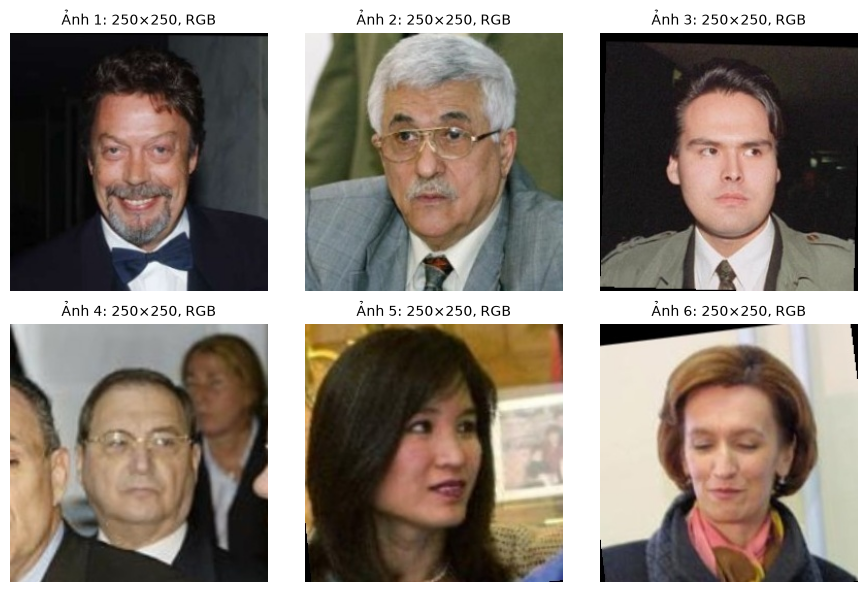

Đã lưu hình tại: C:\Users\mrddd\Documents\FaceDetection_Week4\reports\figures\lfw_source_examples.png


In [11]:
import matplotlib.pyplot as plt

if raw_image_info.empty:
    raise ValueError("Chưa có ảnh đọc được thông tin để hiển thị.")

# Chọn tối đa 6 ảnh; cố định seed để có thể chọn lại cùng mẫu
sampled_sources = raw_image_info.sample(
    n=min(6, len(raw_image_info)),
    random_state=42
)

fig, axes = plt.subplots(2, 3, figsize=(9, 6))

for ax in axes.flat:
    ax.axis("off")

for i, (ax, row) in enumerate(
    zip(axes.flat, sampled_sources.itertuples(index=False)),
    start=1
):
    with Image.open(PROJECT_DIR / row.source_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"Ảnh {i}: {row.width}×{row.height}, {row.mode}",
        fontsize=10
    )

fig.tight_layout()

figure_dir = PROJECT_DIR / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "lfw_source_examples.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")

plt.show()
print("Đã lưu hình tại:", figure_path.resolve())

In [12]:
# Lưu thông tin ảnh nguồn và danh sách ảnh minh họa
metadata_dir = PROJECT_DIR / "data" / "metadata"
metadata_dir.mkdir(parents=True, exist_ok=True)

# Một dòng tương ứng với thông tin của một file JPEG nguồn
image_info_path = metadata_dir / "lfw_source_image_info.csv"
raw_image_info.to_csv(
    image_info_path,
    index=False,
    encoding="utf-8-sig"
)

# Lưu chính xác những ảnh đã xuất hiện trong hình minh họa
example_list_path = metadata_dir / "lfw_example_sources.csv"
sampled_sources[["source_image_id", "source_path"]].to_csv(
    example_list_path,
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu thông tin ảnh:", image_info_path.resolve())
print("Đã lưu danh sách ảnh minh họa:", example_list_path.resolve())

Đã lưu thông tin ảnh: C:\Users\mrddd\Documents\FaceDetection_Week4\data\metadata\lfw_source_image_info.csv
Đã lưu danh sách ảnh minh họa: C:\Users\mrddd\Documents\FaceDetection_Week4\data\metadata\lfw_example_sources.csv


In [13]:
from urllib.request import urlopen
import shutil

# Lưu gói dữ liệu vào thư mục ảnh nền của dự án
CALTECH_DIR = PROJECT_DIR / "data" / "raw" / "backgrounds" / "caltech101"
CALTECH_DIR.mkdir(parents=True, exist_ok=True)

CALTECH_URL = (
    "https://data.caltech.edu/records/"
    "mzrjq-6wc02/files/caltech-101.zip"
)
CALTECH_ZIP = CALTECH_DIR / "caltech-101.zip"

if CALTECH_ZIP.exists():
    print("Đã có tệp, chuyển sang cell kiểm tra:", CALTECH_ZIP)
else:
    # Dùng đuôi .part trong lúc tải để phân biệt với tệp tải hoàn tất
    temporary_path = CALTECH_DIR / "caltech-101.zip.part"

    print("Đang tải Caltech-101, vui lòng chờ...", flush=True)

    with urlopen(CALTECH_URL, timeout=60) as response:
        with temporary_path.open("wb") as output_file:
            shutil.copyfileobj(response, output_file)

    temporary_path.replace(CALTECH_ZIP)
    print("Tải xong:", CALTECH_ZIP.resolve())

Đang tải Caltech-101, vui lòng chờ...


HTTPError: HTTP Error 403: Forbidden

In [14]:
from uuid import uuid4
from IPython.display import display, Markdown

# Thêm mã ngẫu nhiên để thử tránh dùng lại phản hồi chuyển hướng đã lưu
fresh_url = (
    "https://data.caltech.edu/records/mzrjq-6wc02/files/"
    f"caltech-101.zip?download=1&nocache={uuid4().hex}"
)

display(Markdown(f"[Bấm vào đây để tải Caltech-101]({fresh_url})"))

[Bấm vào đây để tải Caltech-101](https://data.caltech.edu/records/mzrjq-6wc02/files/caltech-101.zip?download=1&nocache=e2ab4bc077534f578573218b1f1b265f)

In [23]:
import hashlib
import zipfile

# Mã kiểm tra do nguồn phân phối công bố
EXPECTED_MD5 = "3138e1922a9193bfa496528edbbc45d0"

# Tính MD5 từ tệp thực tế vừa tải
with CALTECH_ZIP.open("rb") as file:
    actual_md5 = hashlib.file_digest(file, "md5").hexdigest()

print("Dung lượng thực tế (MB):", round(CALTECH_ZIP.stat().st_size / 1_000_000, 2))
print("MD5 thực tế:", actual_md5)
print("MD5 khớp nguồn:", actual_md5 == EXPECTED_MD5)

# Dừng nếu tệp chưa khớp với bản công bố
if actual_md5 != EXPECTED_MD5:
    raise ValueError("MD5 không khớp. Cần kiểm tra lại tệp tải về.")

# Xem tên tệp bên trong ZIP, chưa giải nén
with zipfile.ZipFile(CALTECH_ZIP, "r") as archive:
    archive_members = [
        name for name in archive.namelist()
        if not name.startswith("__MACOSX/")
        and not name.endswith("/")
    ]

print("\nCác tệp bên trong gói:")
for name in archive_members[:10]:
    print(name)

Dung lượng thực tế (MB): 137.41
MD5 thực tế: 3138e1922a9193bfa496528edbbc45d0
MD5 khớp nguồn: True

Các tệp bên trong gói:
caltech-101/101_ObjectCategories.tar.gz
caltech-101/show_annotation.m
caltech-101/Annotations.tar


In [22]:
# Kiểm tra vị trí tệp trước khi tính MD5
print("Jupyter đang tìm tại:", CALTECH_ZIP.resolve())
print("Tìm thấy tệp:", CALTECH_ZIP.is_file())

# Liệt kê tên các tệp thực tế trong thư mục đích
print("\nCác tệp đang có trong thư mục:")
for path in CALTECH_ZIP.parent.iterdir():
    if path.is_file():
        print(path.name)

Jupyter đang tìm tại: C:\Users\mrddd\Documents\FaceDetection_Week4\data\raw\backgrounds\caltech101\caltech-101.zip
Tìm thấy tệp: True

Các tệp đang có trong thư mục:
caltech-101.zip


In [24]:
import zipfile
import shutil

# Lưu gói ảnh bên cạnh tệp ZIP đã tải
IMAGE_TAR = CALTECH_ZIP.parent / "101_ObjectCategories.tar.gz"

# Đường dẫn này đã xuất hiện trong kết quả kiểm tra ZIP của bạn
member_name = "caltech-101/101_ObjectCategories.tar.gz"

with zipfile.ZipFile(CALTECH_ZIP, "r") as archive:
    with archive.open(member_name) as source:
        with IMAGE_TAR.open("wb") as destination:
            shutil.copyfileobj(source, destination)

print("Đã lấy gói ảnh:", IMAGE_TAR.resolve())

Đã lấy gói ảnh: C:\Users\mrddd\Documents\FaceDetection_Week4\data\raw\backgrounds\caltech101\101_ObjectCategories.tar.gz


In [25]:
import tarfile
from pathlib import PurePosixPath

# Thư mục lưu ảnh nền ứng viên
BACKGROUND_DIR = (
    PROJECT_DIR / "data" / "raw" / "backgrounds"
    / "caltech101" / "BACKGROUND_Google"
)
BACKGROUND_DIR.mkdir(parents=True, exist_ok=True)

extracted_paths = []

with tarfile.open(IMAGE_TAR, "r:gz") as archive:
    for member in archive:
        member_path = PurePosixPath(member.name)

        # Chỉ lấy file JPEG nằm trực tiếp trong nhóm BACKGROUND_Google
        if (
            member.isfile()
            and member_path.parent.name == "BACKGROUND_Google"
            and member_path.suffix.lower() in {".jpg", ".jpeg"}
        ):
            destination_path = BACKGROUND_DIR / member_path.name

            with archive.extractfile(member) as source:
                with destination_path.open("wb") as destination:
                    shutil.copyfileobj(source, destination)

            extracted_paths.append(destination_path)

# Giữ danh sách để dùng cho bước kiểm kê tiếp theo
background_jpg_files = sorted(extracted_paths)

if not background_jpg_files:
    raise ValueError("Không tìm thấy ảnh JPEG trong nhóm BACKGROUND_Google.")

print("Số ảnh nền ứng viên lấy được:", len(background_jpg_files))
print("Thư mục lưu:", BACKGROUND_DIR.resolve())

print("\nVí dụ tên file:")
for file_path in background_jpg_files[:5]:
    print(file_path.name)

Số ảnh nền ứng viên lấy được: 467
Thư mục lưu: C:\Users\mrddd\Documents\FaceDetection_Week4\data\raw\backgrounds\caltech101\BACKGROUND_Google

Ví dụ tên file:
image_0001.jpg
image_0002.jpg
image_0003.jpg
image_0004.jpg
image_0005.jpg


In [26]:
from PIL import Image
import pandas as pd

background_rows = []
background_read_errors = []

for file_path in background_jpg_files:
    try:
        with Image.open(file_path) as image:
            # Yêu cầu giải mã dữ liệu pixel
            image.load()

            background_rows.append({
                "source_image_id": f"Caltech101/BACKGROUND_Google/{file_path.name}",
                "source_path": file_path.relative_to(PROJECT_DIR).as_posix(),
                "filename": file_path.name,
                "width": image.width,
                "height": image.height,
                "mode": image.mode,
                "file_format": image.format
            })

    except Exception as loi:
        background_read_errors.append({
            "filename": file_path.name,
            "error": f"{type(loi).__name__}: {loi}"
        })

background_info = pd.DataFrame(background_rows)

print("Số file đã kiểm tra:", len(background_jpg_files))
print("Số file đọc thành công:", len(background_info))
print("Số file gặp lỗi:", len(background_read_errors))

if not background_info.empty:
    print("\nPhân bố chế độ màu và định dạng:")
    display(
        background_info.groupby(["mode", "file_format"])
        .size()
        .reset_index(name="n_images")
    )

    print("Thống kê kích thước ảnh:")
    display(background_info[["width", "height"]].describe())

if background_read_errors:
    display(pd.DataFrame(background_read_errors))

Số file đã kiểm tra: 467
Số file đọc thành công: 467
Số file gặp lỗi: 0

Phân bố chế độ màu và định dạng:


,mode,file_format,n_images
0,L,JPEG,30
1,RGB,JPEG,437


Thống kê kích thước ảnh:


,width,height
count,467.000000,467.000000
mean,374.265525,340.089936
std,294.735668,295.866061
min,140.000000,132.000000
25%,198.000000,188.500000
50%,298.000000,250.000000
75%,460.000000,388.000000
max,3481.000000,3999.000000


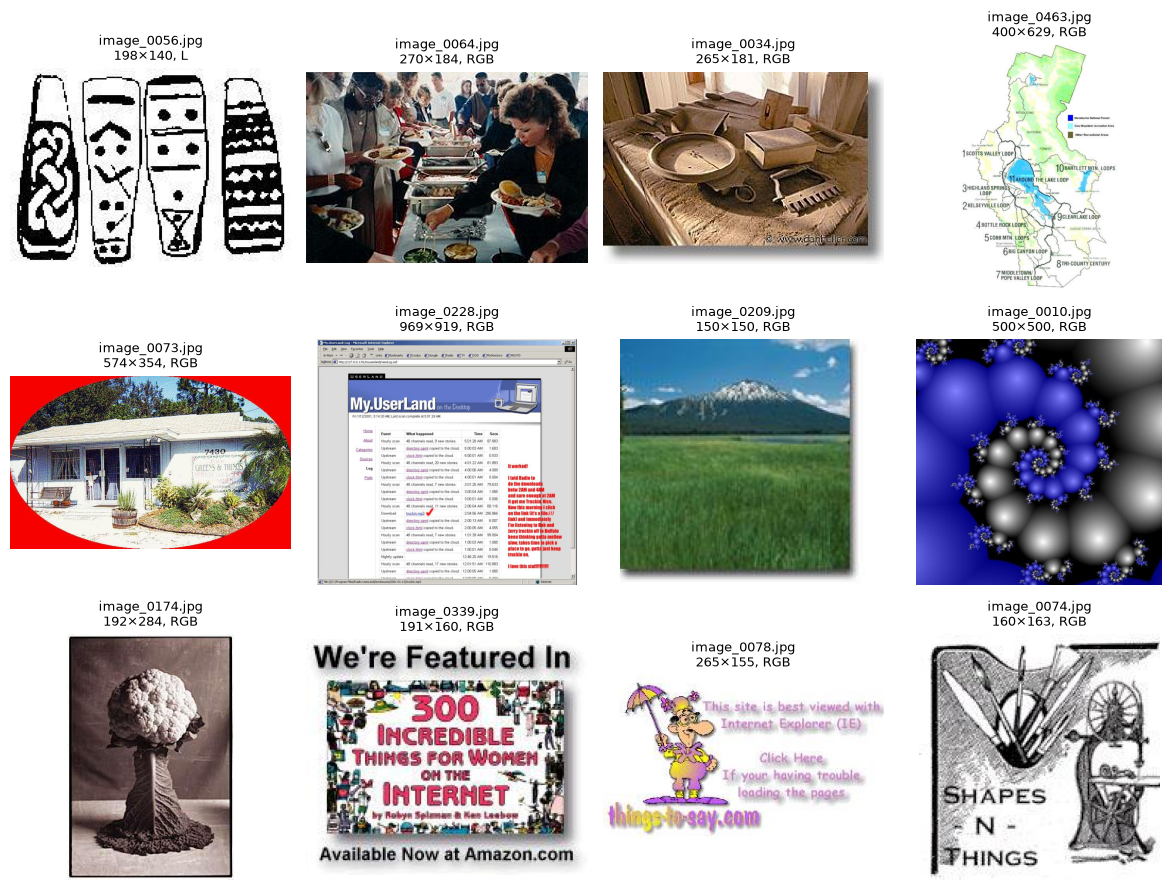

Đã lưu hình: C:\Users\mrddd\Documents\FaceDetection_Week4\reports\figures\caltech_background_candidates.png


In [27]:
import matplotlib.pyplot as plt

if background_info.empty:
    raise ValueError("Chưa có ảnh đọc thành công để hiển thị.")

# Chọn ảnh có thể tái lập; giữ tên file để truy lại khi kiểm tra
background_examples = background_info.sample(
    n=min(12, len(background_info)),
    random_state=42
)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax in axes.flat:
    ax.axis("off")

for ax, row in zip(
    axes.flat,
    background_examples.itertuples(index=False)
):
    with Image.open(PROJECT_DIR / row.source_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"{row.filename}\n{row.width}×{row.height}, {row.mode}",
        fontsize=9
    )

fig.tight_layout()

figure_dir = PROJECT_DIR / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "caltech_background_candidates.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")

plt.show()
print("Đã lưu hình:", figure_path.resolve())

In [28]:
# Lưu thông tin nguồn cùng trạng thái kiểm tra nội dung
background_metadata_path = (
    PROJECT_DIR / "data" / "metadata" / "caltech_background_sources.csv"
)
background_metadata_path.parent.mkdir(parents=True, exist_ok=True)

if background_metadata_path.exists():
    # Đọc lại kết quả đã lưu để giữ các lần kiểm tra trước
    background_sources = pd.read_csv(
        background_metadata_path,
        dtype={"label": "Int64"}
    )
else:
    background_sources = background_info.copy()
    background_sources["dataset"] = "Caltech101_BACKGROUND_Google"

    # Nhãn còn thiếu cho đến khi nội dung được kiểm tra
    background_sources["label"] = pd.Series(
        pd.NA, index=background_sources.index, dtype="Int64"
    )
    background_sources["review_status"] = "not_reviewed"
    background_sources["review_note"] = ""

    background_sources.to_csv(
        background_metadata_path,
        index=False,
        encoding="utf-8-sig"
    )

print("Số ảnh trong bảng:", len(background_sources))
print(background_sources["review_status"].value_counts())
print("Đã lưu tại:", background_metadata_path.resolve())

Số ảnh trong bảng: 467
review_status
not_reviewed    467
Name: count, dtype: int64
Đã lưu tại: C:\Users\mrddd\Documents\FaceDetection_Week4\data\metadata\caltech_background_sources.csv


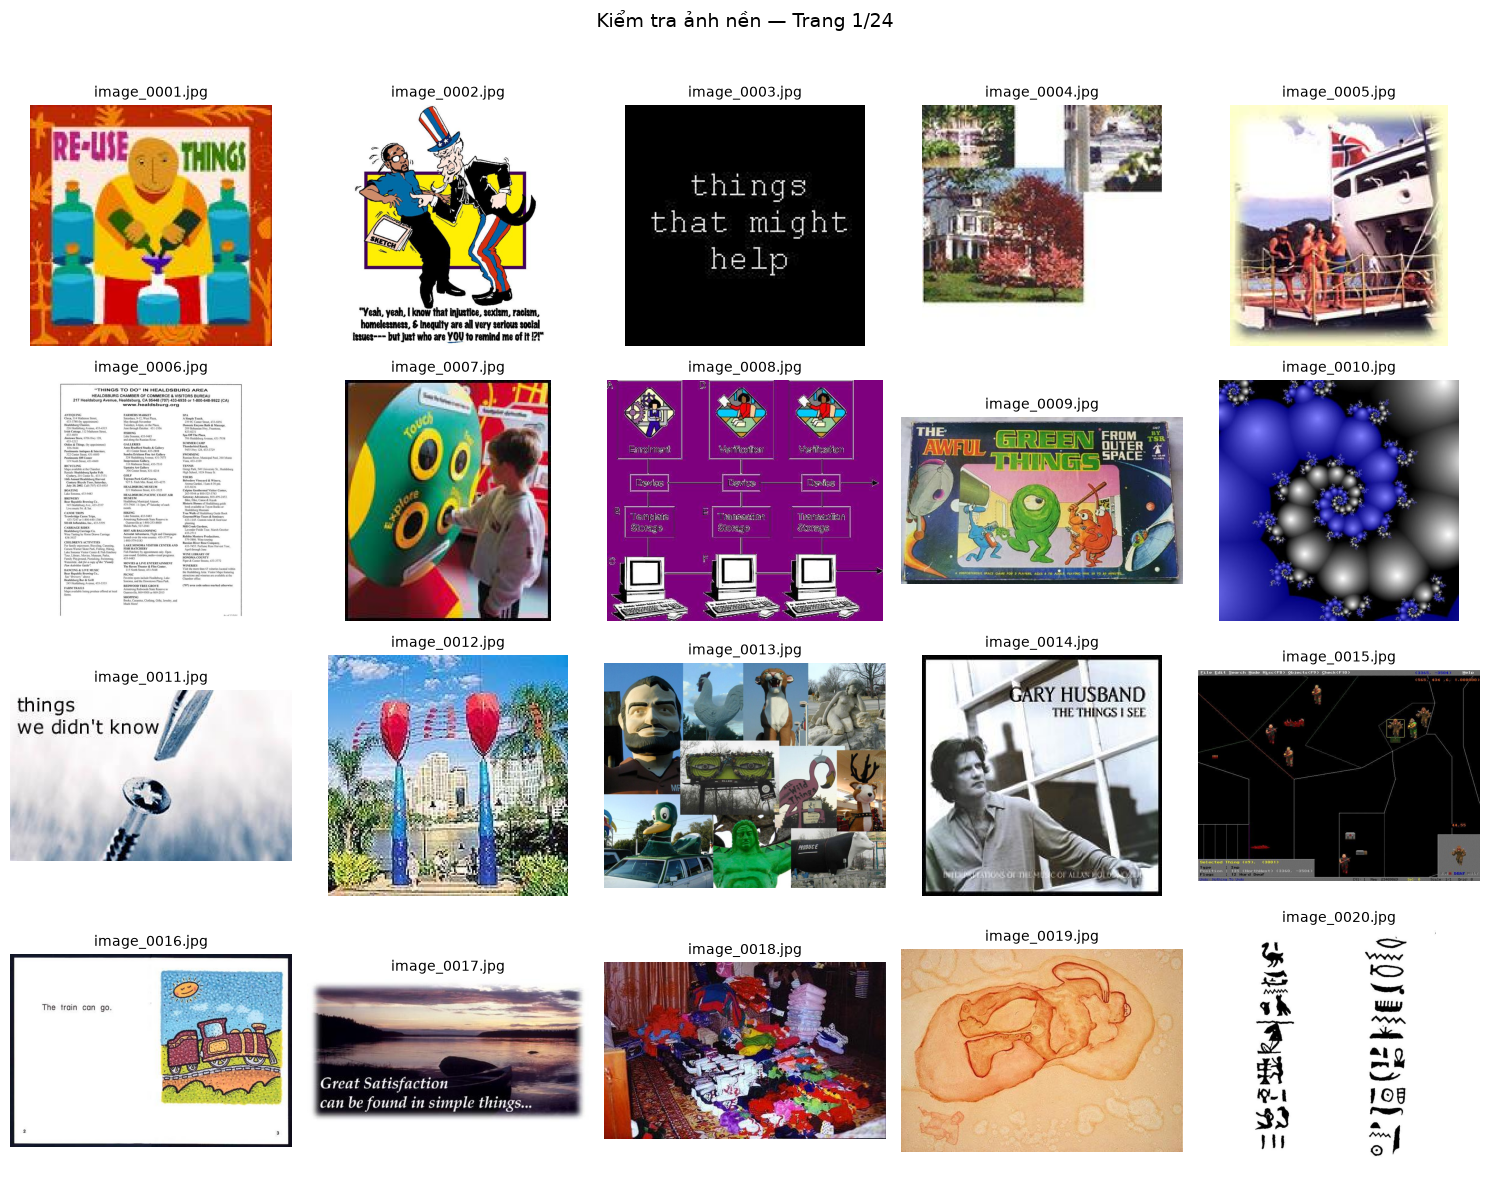

In [30]:
from PIL import Image
import matplotlib.pyplot as plt

# Đổi số trang để xem các nhóm ảnh tiếp theo
page = 1
page_size = 20

ordered_sources = background_sources.sort_values("filename")
total_pages = (len(ordered_sources) + page_size - 1) // page_size

if not 1 <= page <= total_pages:
    raise ValueError(f"Số trang phải từ 1 đến {total_pages}.")

start = (page - 1) * page_size
page_sources = ordered_sources.iloc[start:start + page_size]

fig, axes = plt.subplots(4, 5, figsize=(15, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, row in zip(
    axes.flat,
    page_sources.itertuples(index=False)
):
    with Image.open(PROJECT_DIR / row.source_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(row.filename, fontsize=10)

fig.suptitle(
    f"Kiểm tra ảnh nền — Trang {page}/{total_pages}",
    fontsize=14
)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [42]:
# Điền số ảnh theo kết quả bạn đã quan sát trên trang 1
accepted_ids = []     # Đã kiểm tra và không thấy khuôn mặt người
rejected_ids = [13,14]     # Có khuôn mặt người
uncertain_ids = []    # Chưa rõ hoặc cần kiểm tra thêm

review_groups = {
    "accepted_nonface": accepted_ids,
    "rejected_face": rejected_ids,
    "uncertain": uncertain_ids
}

# Chuyển số ảnh thành tên file
review_files = {
    status: [f"image_{number:04d}.jpg" for number in numbers]
    for status, numbers in review_groups.items()
}

all_files = [
    filename
    for filenames in review_files.values()
    for filename in filenames
]

# Một ảnh chỉ được xuất hiện một lần trong lần cập nhật này
if len(all_files) != len(set(all_files)):
    raise ValueError("Có ảnh bị nhập lặp hoặc xuất hiện trong nhiều nhóm.")

# Chỉ cho phép cập nhật ảnh thuộc trang đang hiển thị
current_page_files = set(page_sources["filename"])

if not set(all_files).issubset(current_page_files):
    raise ValueError("Có tên ảnh không thuộc trang đang hiển thị.")

if not all_files:
    print("Chưa nhập ảnh nào; chưa cập nhật dữ liệu.")
else:
    updated_sources = background_sources.copy()

    for status, filenames in review_files.items():
        mask = updated_sources["filename"].isin(filenames)

        updated_sources.loc[mask, "review_status"] = status
        updated_sources.loc[mask, "label"] = (
            0 if status == "accepted_nonface" else pd.NA
        )
        updated_sources.loc[mask, "review_note"] = (
            f"Kiểm tra thủ công ở trang {page}"
        )

    # Lưu trước, rồi cập nhật bảng đang dùng trong notebook
    updated_sources.to_csv(
        background_metadata_path,
        index=False,
        encoding="utf-8-sig"
    )
    background_sources = updated_sources

    print("Số ảnh cập nhật lần này:", len(all_files))
    print("\nTrạng thái toàn bộ nguồn ảnh nền:")
    print(background_sources["review_status"].value_counts())

Số ảnh cập nhật lần này: 2

Trạng thái toàn bộ nguồn ảnh nền:
review_status
not_reviewed     461
rejected_face      3
uncertain          3
Name: count, dtype: int64


,filename,review_status,review_note
12,image_0013.jpg,rejected_face,Kiểm tra thủ công ở trang 1
13,image_0014.jpg,rejected_face,Kiểm tra thủ công ở trang 1


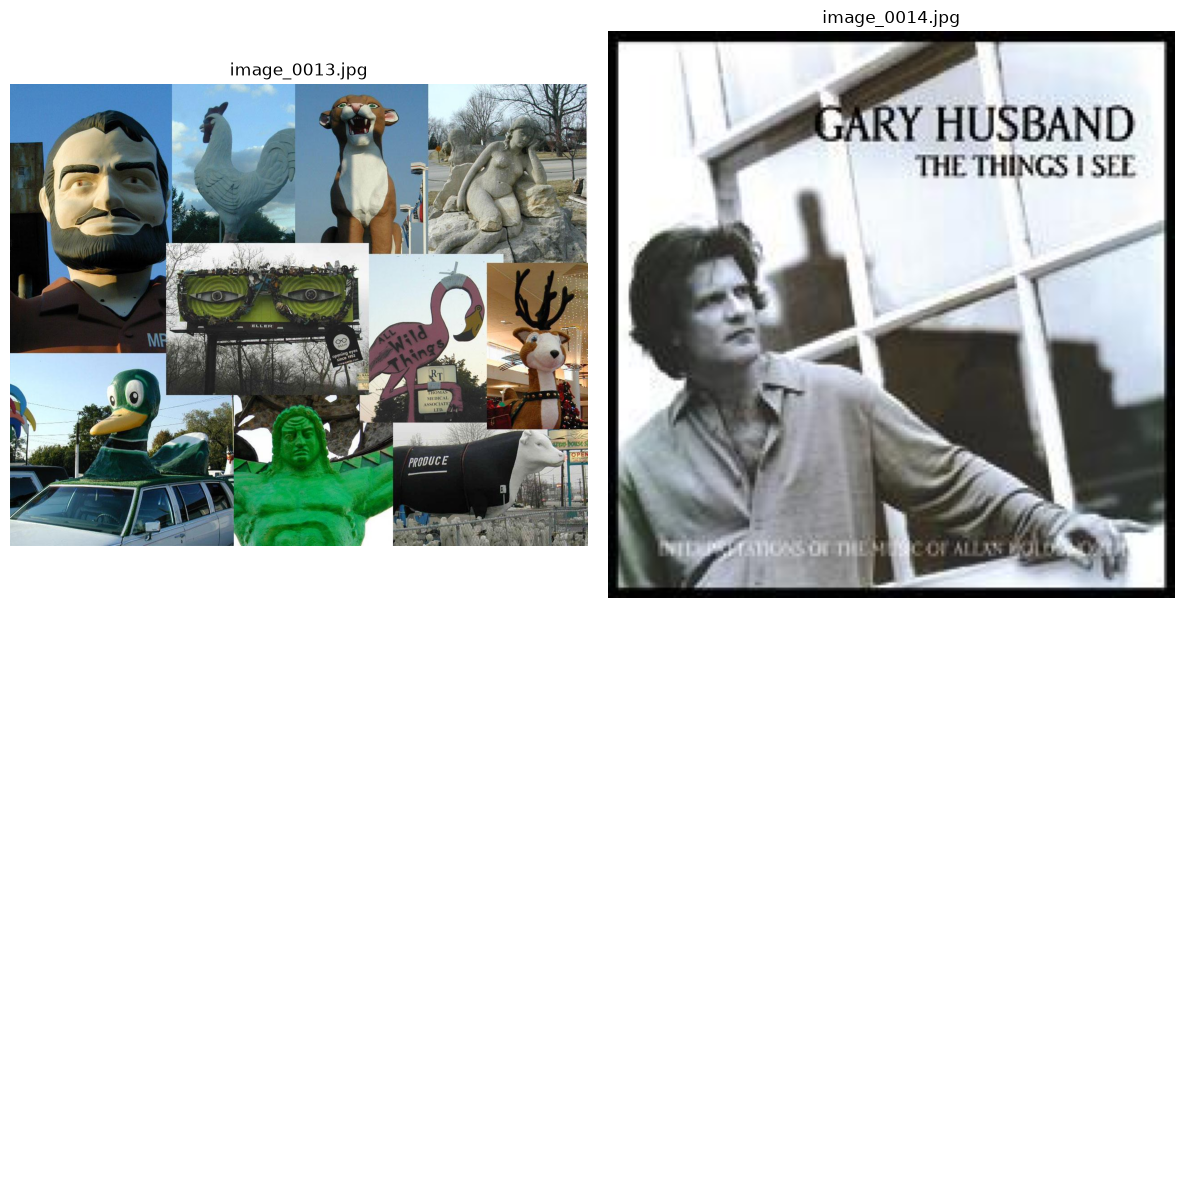

In [45]:
# Kiểm tra lại các ảnh đang được ghi nhận là có khuôn mặt
rejected_rows = background_sources.loc[
    background_sources["review_status"] == "rejected_face"
].sort_values("filename")

display(rejected_rows[["filename", "review_status", "review_note"]])

# Hiển thị tối đa 4 ảnh đầu tiên với kích thước lớn hơn
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, row in zip(
    axes.flat,
    rejected_rows.head(4).itertuples(index=False)
):
    with Image.open(PROJECT_DIR / row.source_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(row.filename, fontsize=12)

fig.tight_layout()
plt.show()

In [44]:
# Các ảnh cần xem lại quyết định loại
files_to_recheck = [
    "image_0010.jpg"
]

updated_sources = background_sources.copy()
mask = updated_sources["filename"].isin(files_to_recheck)

# Chuyển sang chờ xác minh, bỏ nhãn nếu đã gán
updated_sources.loc[mask, "review_status"] = "uncertain"
updated_sources.loc[mask, "label"] = pd.NA
updated_sources.loc[mask, "review_note"] = (
    "Cần xem lại nội dung; chưa xác nhận có khuôn mặt người."
)

updated_sources.to_csv(
    background_metadata_path,
    index=False,
    encoding="utf-8-sig"
)
background_sources = updated_sources

print("Đã lưu trạng thái điều chỉnh:")
display(
    background_sources.loc[
        mask, ["filename", "review_status", "label", "review_note"]
    ]
)

print("\nThống kê trạng thái hiện tại:")
print(background_sources["review_status"].value_counts())

Đã lưu trạng thái điều chỉnh:


,filename,review_status,label,review_note
9,image_0010.jpg,uncertain,<NA>,Cần xem lại nội dung; chưa xác nhận có khuôn m...



Thống kê trạng thái hiện tại:
review_status
not_reviewed     461
uncertain          4
rejected_face      2
Name: count, dtype: int64


## 4. Khảo sát thống kê và phân bố dữ liệu

### 4.1. Quy mô nguồn ảnh và phân bố nhãn hiện có

In [46]:
import pandas as pd

# Đọc lại các CSV để sử dụng kết quả đã lưu gần nhất
metadata_dir = PROJECT_DIR / "data" / "metadata"

eda_faces = pd.read_csv(
    metadata_dir / "lfw_face_sources.csv",
    dtype={"label": "Int64"}
)

eda_backgrounds = pd.read_csv(
    metadata_dir / "caltech_background_sources.csv",
    dtype={"label": "Int64"}
)

# Thống kê quy mô từng nguồn
source_summary = pd.DataFrame({
    "nguon": ["LFW funneled", "Caltech-101: ảnh nền ứng viên"],
    "so_anh": [len(eda_faces), len(eda_backgrounds)]
})

print("QUY MÔ NGUỒN ẢNH")
display(source_summary)

# Ghép cột nhãn; các nhãn chưa xác định vẫn được giữ là thiếu
eda_labels = pd.concat(
    [eda_faces["label"], eda_backgrounds["label"]],
    ignore_index=True
)

label_summary = pd.DataFrame({
    "nhom": [
        "Face theo nhãn nguồn",
        "Non-face đã chấp nhận",
        "Chưa xác định"
    ],
    "so_anh": [
        int(eda_labels.eq(1).sum()),
        int(eda_labels.eq(0).sum()),
        int(eda_labels.isna().sum())
    ]
})

label_summary["ty_le_phan_tram"] = (
    label_summary["so_anh"] / len(eda_labels) * 100
).round(2)

print("PHÂN BỐ NHÃN TRONG DANH MỤC ẢNH NGUỒN")
display(label_summary)

QUY MÔ NGUỒN ẢNH


,nguon,so_anh
0,LFW funneled,13233
1,Caltech-101: ảnh nền ứng viên,467


PHÂN BỐ NHÃN TRONG DANH MỤC ẢNH NGUỒN


,nhom,so_anh,ty_le_phan_tram
0,Face theo nhãn nguồn,13233,96.59
1,Non-face đã chấp nhận,0,0.00
2,Chưa xác định,467,3.41


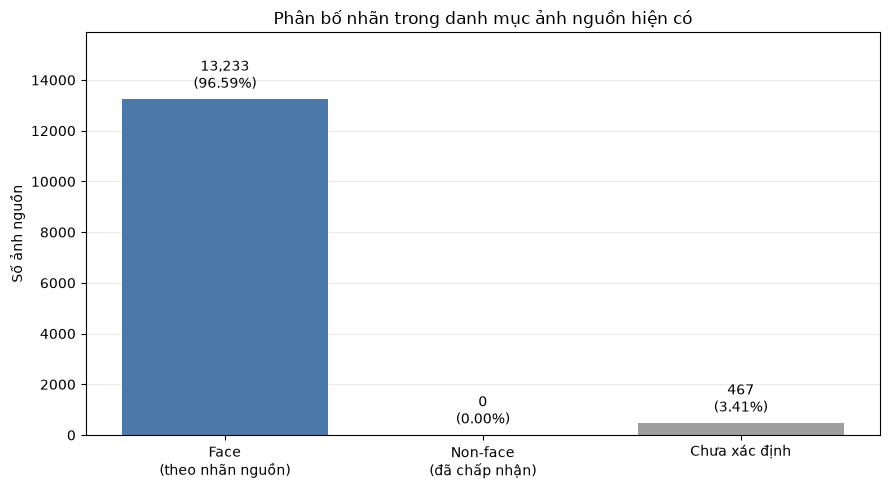

Đã lưu biểu đồ: C:\Users\mrddd\Documents\FaceDetection_Week4\reports\figures\eda_source_label_distribution.png


In [47]:
import matplotlib.pyplot as plt

plot_names = [
    "Face\n(theo nhãn nguồn)",
    "Non-face\n(đã chấp nhận)",
    "Chưa xác định"
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    plot_names,
    label_summary["so_anh"],
    color=["#4C78A8", "#F58518", "#9E9E9E"]
)

# Ghi số lượng và tỷ lệ lên từng cột
for bar, count, percent in zip(
    bars,
    label_summary["so_anh"],
    label_summary["ty_le_phan_tram"]
):
    ax.annotate(
        f"{count:,}\n({percent:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_title("Phân bố nhãn trong danh mục ảnh nguồn hiện có")
ax.set_ylabel("Số ảnh nguồn")
ax.margins(y=0.2)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()

figure_dir = PROJECT_DIR / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "eda_source_label_distribution.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")

plt.show()
print("Đã lưu biểu đồ:", figure_path.resolve())

### 4.2. Thống kê độ sáng và độ phân tán cường độ xám

In [48]:
import numpy as np
from PIL import Image

# Ghép danh mục nguồn; giữ mã ảnh để truy lại kết quả
eda_sources = pd.concat(
    [
        eda_faces.assign(nguon="LFW funneled"),
        eda_backgrounds.assign(nguon="Caltech-101: ứng viên nền")
    ],
    ignore_index=True
)

pixel_records = []
pixel_errors = []

for i, row in enumerate(
    eda_sources.itertuples(index=False), start=1
):
    try:
        with Image.open(PROJECT_DIR / row.source_path) as image:
            # Áp dụng cùng cách chuyển xám cho cả hai nguồn
            gray = np.asarray(
                image.convert("L"),
                dtype=np.float32
            )

            pixel_records.append({
                "source_image_id": row.source_image_id,
                "nguon": row.nguon,
                "mean_gray": float(gray.mean()),
                "std_gray": float(gray.std())
            })

    except Exception as loi:
        pixel_errors.append({
            "source_image_id": row.source_image_id,
            "error": f"{type(loi).__name__}: {loi}"
        })

    # Hiển thị tiến độ, tránh in một dòng cho mỗi ảnh
    if i % 2000 == 0 or i == len(eda_sources):
        print(f"Đã xử lý {i}/{len(eda_sources)} ảnh", flush=True)

eda_pixel_stats = pd.DataFrame(pixel_records)

print("\nSố ảnh tính được thống kê:", len(eda_pixel_stats))
print("Số ảnh gặp lỗi:", len(pixel_errors))

if not eda_pixel_stats.empty:
    display(
        eda_pixel_stats.groupby("nguon")[
            ["mean_gray", "std_gray"]
        ].describe().round(2)
    )

    # Lưu kết quả để vẽ biểu đồ ở bước tiếp theo
    stats_path = metadata_dir / "eda_source_pixel_stats.csv"
    eda_pixel_stats.to_csv(
        stats_path, index=False, encoding="utf-8-sig"
    )
    print("Đã lưu:", stats_path.resolve())

if pixel_errors:
    display(pd.DataFrame(pixel_errors))

Đã xử lý 2000/13700 ảnh
Đã xử lý 4000/13700 ảnh
Đã xử lý 6000/13700 ảnh
Đã xử lý 8000/13700 ảnh
Đã xử lý 10000/13700 ảnh
Đã xử lý 12000/13700 ảnh
Đã xử lý 13700/13700 ảnh

Số ảnh tính được thống kê: 13700
Số ảnh gặp lỗi: 0


mean_gray                                        \
                              count    mean    std    min     25%     50%   
nguon                                                                       
Caltech-101: ứng viên nền     467.0  148.73  54.15   6.87  108.66  145.63   
LFW funneled                13233.0   98.97  28.19  22.09   78.39   96.84   

                                          std_gray                       \
                              75%     max    count   mean    std    min   
nguon                                                                     
Caltech-101: ứng viên nền  192.68  252.87    467.0  64.06  17.40   4.65   
LFW funneled               117.57  204.68  13233.0  62.70  11.31  24.14   

                                                        
                             25%    50%    75%     max  
nguon                                                   
Caltech-101: ứng viên nền  52.68  63.39  77.26  112.15  
LFW funneled               54.94  62.14  69.90  105.90

Đã lưu: C:\Users\mrddd\Documents\FaceDetection_Week4\data\metadata\eda_source_pixel_stats.csv


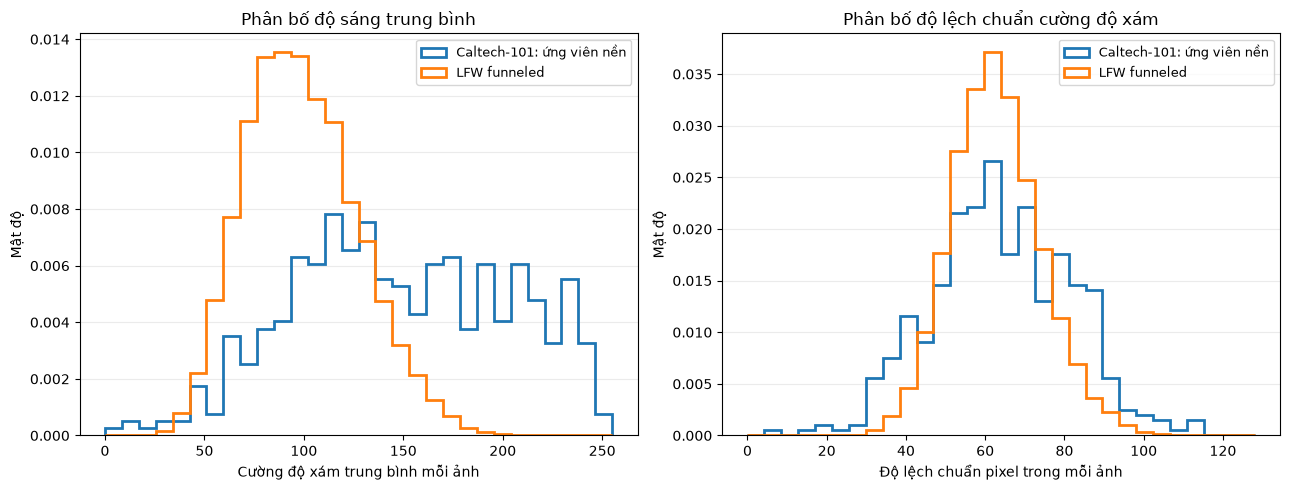

Đã lưu hình: C:\Users\mrddd\Documents\FaceDetection_Week4\reports\figures\eda_brightness_contrast_by_source.png


In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Đọc các đại lượng đã tính
eda_pixel_stats = pd.read_csv(
    PROJECT_DIR / "data" / "metadata" / "eda_source_pixel_stats.csv",
    encoding="utf-8-sig"
)

# Mỗi biểu đồ dùng cùng các khoảng chia cho cả hai nguồn
plot_settings = [
    (
        "mean_gray",
        np.linspace(0, 255, 31),
        "Phân bố độ sáng trung bình",
        "Cường độ xám trung bình mỗi ảnh"
    ),
    (
        "std_gray",
        np.linspace(0, 128, 31),
        "Phân bố độ lệch chuẩn cường độ xám",
        "Độ lệch chuẩn pixel trong mỗi ảnh"
    )
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (feature, bins, title, xlabel) in zip(axes, plot_settings):
    for source_name, group in eda_pixel_stats.groupby("nguon"):
        ax.hist(
            group[feature].dropna(),
            bins=bins,
            density=True,
            histtype="step",
            linewidth=2,
            label=source_name
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Mật độ")
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

figure_dir = PROJECT_DIR / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "eda_brightness_contrast_by_source.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")

plt.show()
print("Đã lưu hình:", figure_path.resolve())

Số dòng hợp lệ: 13700
Số dòng bị loại khỏi phân tích: 0

Tương quan giữa mean_gray và std_gray theo nguồn:


,nguon,so_anh,pearson_r,spearman_rho
0,Caltech-101: ứng viên nền,467,-0.0257,-0.0377
1,LFW funneled,13233,0.2983,0.2820


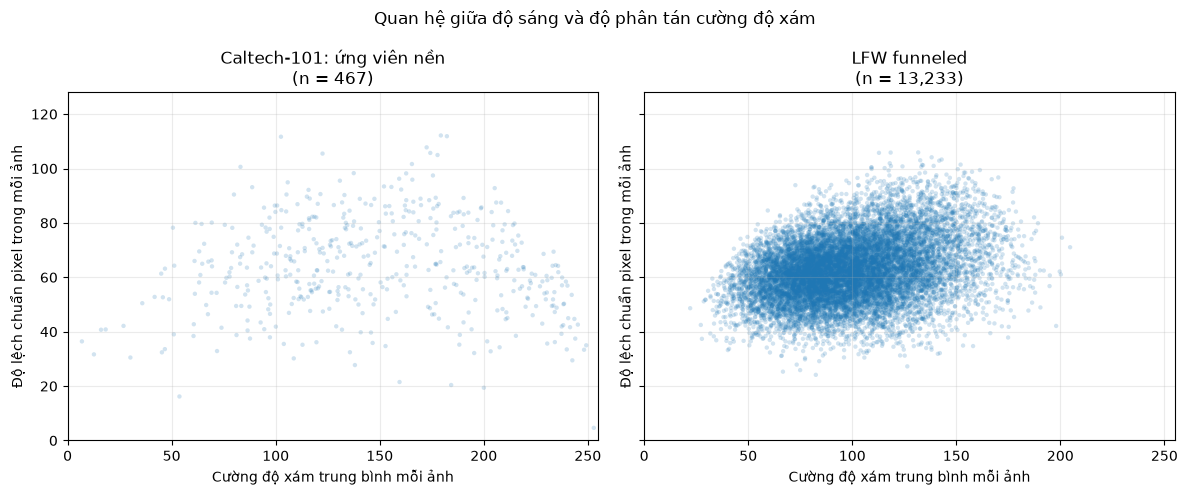

Đã lưu hình: C:\Users\mrddd\Documents\FaceDetection_Week4\reports\figures\eda_mean_std_relationship_by_source.png
Đã lưu bảng: C:\Users\mrddd\Documents\FaceDetection_Week4\data\metadata\eda_mean_std_correlations.csv


In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dùng kết quả đã tính, không cần đọc lại ảnh
stats_path = (
    PROJECT_DIR / "data" / "metadata"
    / "eda_source_pixel_stats.csv"
)
eda_stats = pd.read_csv(stats_path, encoding="utf-8-sig")

features = ["mean_gray", "std_gray"]

# Chỉ dùng các dòng có đủ hai đại lượng hữu hạn
clean_stats = eda_stats.copy()
clean_stats[features] = clean_stats[features].apply(
    pd.to_numeric, errors="coerce"
)
valid = np.isfinite(clean_stats[features]).all(axis=1)
clean_stats = clean_stats.loc[valid].copy()

print("Số dòng hợp lệ:", len(clean_stats))
print("Số dòng bị loại khỏi phân tích:", (~valid).sum())

# Tương quan riêng theo từng nguồn
rows = []

for source_name, group in clean_stats.groupby("nguon"):
    rows.append({
        "nguon": source_name,
        "so_anh": len(group),
        "pearson_r": group["mean_gray"].corr(
            group["std_gray"], method="pearson"
        ),
        "spearman_rho": group["mean_gray"].corr(
            group["std_gray"], method="spearman"
        )
    })

correlation_table = pd.DataFrame(rows)

print("\nTương quan giữa mean_gray và std_gray theo nguồn:")
display(correlation_table.round(4))

# Hai ô dùng cùng thang đo để dễ đối chiếu
groups = list(clean_stats.groupby("nguon"))
fig, axes = plt.subplots(
    1, len(groups),
    figsize=(6 * len(groups), 5),
    sharex=True,
    sharey=True,
    squeeze=False
)

for ax, (source_name, group) in zip(axes.ravel(), groups):
    ax.scatter(
        group["mean_gray"],
        group["std_gray"],
        s=10,
        alpha=0.2,
        edgecolors="none",
        rasterized=True
    )

    ax.set_title(f"{source_name}\n(n = {len(group):,})")
    ax.set_xlabel("Cường độ xám trung bình mỗi ảnh")
    ax.set_ylabel("Độ lệch chuẩn pixel trong mỗi ảnh")
    ax.set_xlim(0, 255)
    ax.set_ylim(0, 128)
    ax.grid(alpha=0.25)

fig.suptitle("Quan hệ giữa độ sáng và độ phân tán cường độ xám")
fig.tight_layout()

figure_dir = PROJECT_DIR / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "eda_mean_std_relationship_by_source.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")

correlation_path = stats_path.parent / "eda_mean_std_correlations.csv"
correlation_table.to_csv(
    correlation_path, index=False, encoding="utf-8-sig"
)

plt.show()
print("Đã lưu hình:", figure_path.resolve())
print("Đã lưu bảng:", correlation_path.resolve())

In [51]:
import pandas as pd

metadata_dir = PROJECT_DIR / "data" / "metadata"
csv_files = sorted(metadata_dir.glob("*.csv"))

if not csv_files:
    print("Không tìm thấy file CSV trong:", metadata_dir)
else:
    for csv_path in csv_files:
        print(f"\n===== {csv_path.name} =====")

        try:
            df_check = pd.read_csv(
                csv_path,
                encoding="utf-8-sig"
            )

            print("Số dòng:", len(df_check))
            print("Các cột:", df_check.columns.tolist())

            # Hiển thị phân bố nhãn hoặc trạng thái nếu có
            for column in df_check.columns:
                name = str(column).strip().lower()

                if name in {
                    "label", "nhan", "nhãn",
                    "status", "review_status", "trang_thai"
                }:
                    print(f"\nPhân bố cột '{column}':")
                    print(
                        df_check[column]
                        .value_counts(dropna=False)
                        .to_string()
                    )

        except Exception as error:
            print("Không đọc được file:", error)


===== caltech_background_sources.csv =====
Số dòng: 467
Các cột: ['source_image_id', 'source_path', 'filename', 'width', 'height', 'mode', 'file_format', 'dataset', 'label', 'review_status', 'review_note']

Phân bố cột 'label':
label
NaN    467

Phân bố cột 'review_status':
review_status
not_reviewed     461
uncertain          4
rejected_face      2

===== eda_mean_std_correlations.csv =====
Số dòng: 2
Các cột: ['nguon', 'so_anh', 'pearson_r', 'spearman_rho']

===== eda_source_pixel_stats.csv =====
Số dòng: 13700
Các cột: ['source_image_id', 'nguon', 'mean_gray', 'std_gray']

===== lfw_example_sources.csv =====
Số dòng: 6
Các cột: ['source_image_id', 'source_path']

===== lfw_face_sources.csv =====
Số dòng: 13233
Các cột: ['source_image_id', 'source_path', 'dataset', 'person_id', 'label', 'review_status']

Phân bố cột 'label':
label
1    13233

Phân bố cột 'review_status':
review_status
not_reviewed    13233

===== lfw_source_image_info.csv =====
Số dòng: 13233
Các cột: ['source_image

XỬ LÍ ẢNH

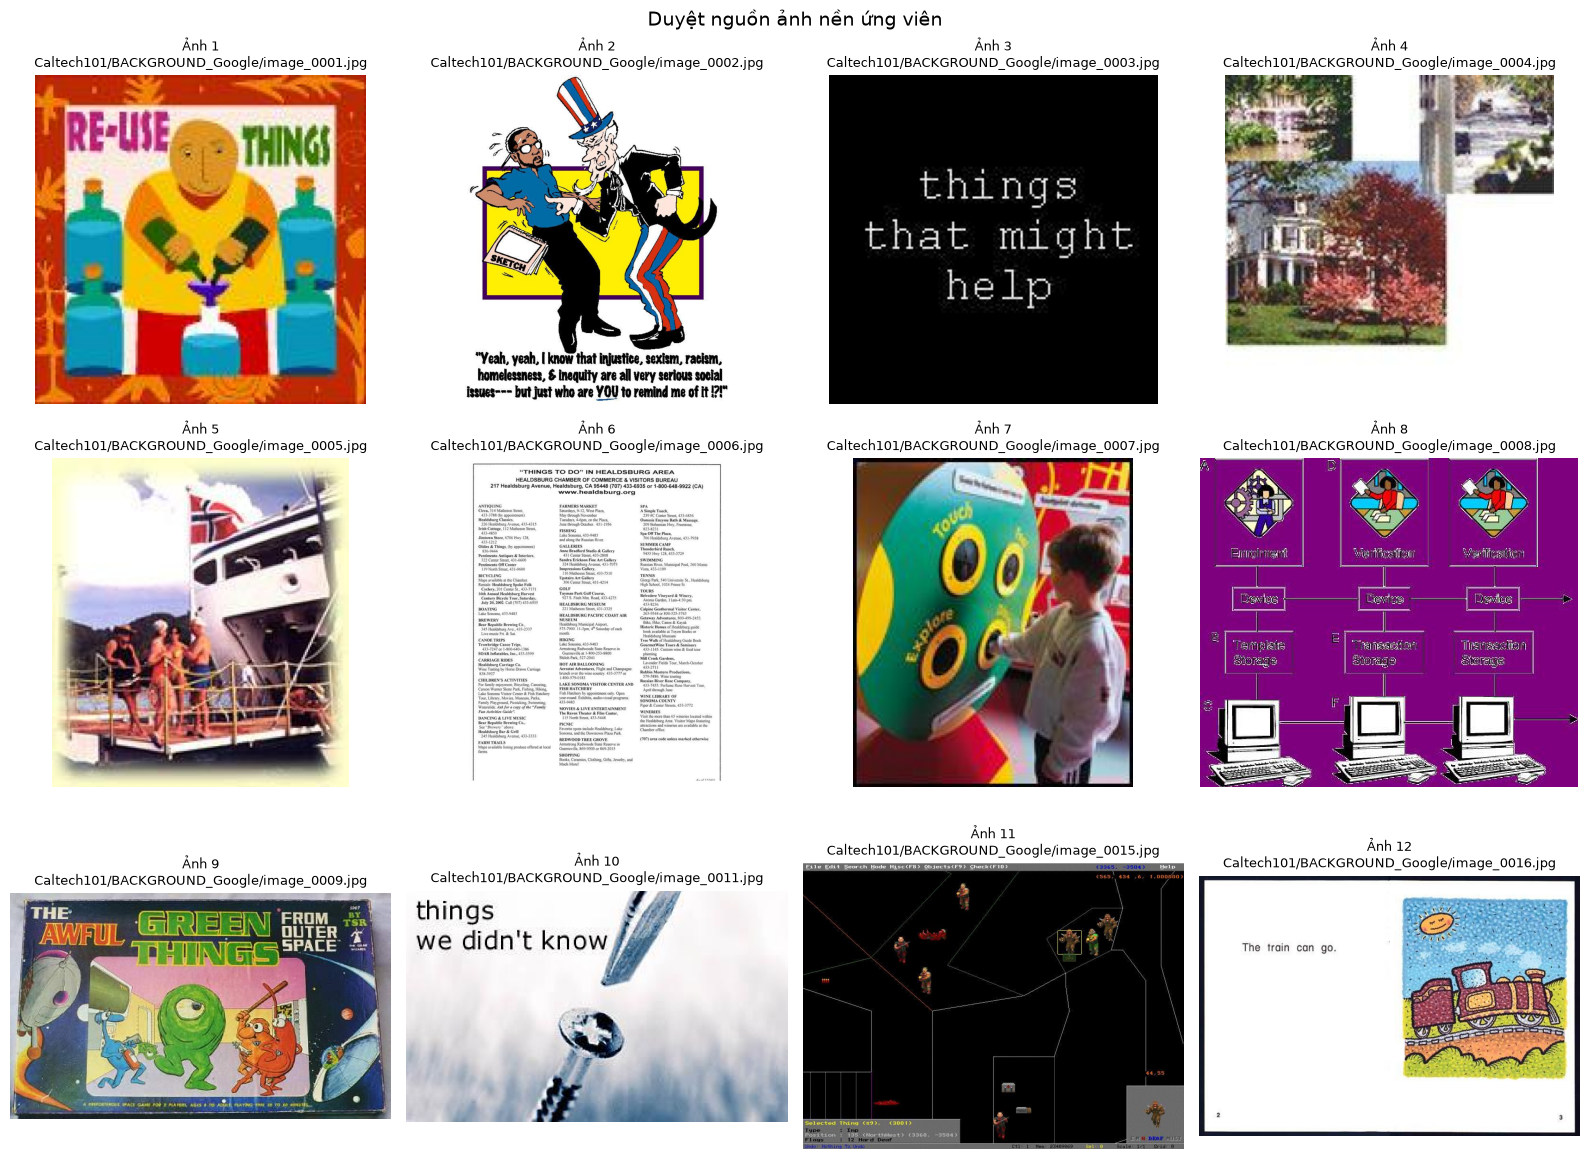

In [52]:
from pathlib import Path
from PIL import Image, ImageOps
import pandas as pd
import matplotlib.pyplot as plt

background_csv = (
    PROJECT_DIR / "data" / "metadata"
    / "caltech_background_sources.csv"
)

background_df = pd.read_csv(
    background_csv,
    encoding="utf-8-sig",
    dtype={"source_image_id": str}
)

# Lấy 12 ảnh chưa duyệt, giữ nguyên thứ tự trong CSV
review_batch = background_df.loc[
    background_df["review_status"].eq("not_reviewed")
].head(12).copy()

if review_batch.empty:
    print("Không còn ảnh có trạng thái not_reviewed.")
else:
    review_batch["preview_no"] = range(1, len(review_batch) + 1)

    fig, axes = plt.subplots(3, 4, figsize=(16, 12))

    for ax in axes.ravel():
        ax.axis("off")

    for ax, (_, row) in zip(axes.ravel(), review_batch.iterrows()):
        image_path = Path(row["source_path"])

        if not image_path.is_absolute():
            image_path = PROJECT_DIR / image_path

        try:
            with Image.open(image_path) as image:
                preview = ImageOps.exif_transpose(image).convert("RGB")
                ax.imshow(preview)

            ax.set_title(
                f"Ảnh {row['preview_no']}\n"
                f"{row['source_image_id']}",
                fontsize=9
            )

        except Exception as error:
            ax.set_title(f"Ảnh {row['preview_no']} — lỗi đọc")
            ax.text(
                0.5, 0.5, str(error),
                ha="center", va="center",
                wrap=True, fontsize=8,
                transform=ax.transAxes
            )

    fig.suptitle("Duyệt nguồn ảnh nền ứng viên", fontsize=14)
    fig.tight_layout()
    plt.show()

In [54]:
from pathlib import Path
from datetime import datetime
from PIL import Image, ImageOps
from IPython.display import clear_output
import pandas as pd
import matplotlib.pyplot as plt
import math
import shutil
import os

# Có thể đổi thành 24 nếu muốn xem nhiều ảnh hơn mỗi trang
BATCH_SIZE = 12

csv_path = (
    PROJECT_DIR / "data" / "metadata"
    / "caltech_background_sources.csv"
)

backup_path = None


def nhap_so_anh(prompt, total):
    text = input(prompt).strip().lower()

    if text == "q":
        return None

    if not text:
        return set()

    numbers = {
        int(value)
        for value in text.replace(",", " ").split()
    }

    if not numbers.issubset(set(range(1, total + 1))):
        raise ValueError(f"Chỉ nhập số từ 1 đến {total}.")

    return numbers


while True:
    # Đọc lại CSV để tiếp tục từ tiến độ đã lưu
    df = pd.read_csv(
        csv_path,
        encoding="utf-8-sig",
        dtype={"source_image_id": str}
    )

    if df["source_image_id"].isna().any():
        raise ValueError("Có source_image_id bị thiếu.")

    if df["source_image_id"].duplicated().any():
        raise ValueError("Có source_image_id bị trùng.")

    if "review_note" not in df.columns:
        df["review_note"] = ""

    df["review_note"] = df["review_note"].fillna("").astype(str)

    pending = df.loc[
        df["review_status"].eq("not_reviewed")
    ]

    clear_output(wait=True)

    if pending.empty:
        print("Đã duyệt hết các ảnh not_reviewed.")
        print("\nThống kê trạng thái:")
        print(df["review_status"].value_counts(dropna=False))
        break

    batch = pending.head(BATCH_SIZE).copy()
    total = len(batch)

    print("Số ảnh còn chưa duyệt:", len(pending))
    print("Số ảnh trên trang này:", total)

    rows = math.ceil(total / 4)
    fig, axes = plt.subplots(
        rows, 4,
        figsize=(16, rows * 4),
        squeeze=False
    )

    for ax in axes.ravel():
        ax.axis("off")

    read_errors = []

    for number, (_, row) in enumerate(batch.iterrows(), start=1):
        ax = axes.ravel()[number - 1]
        image_path = Path(row["source_path"])

        if not image_path.is_absolute():
            image_path = PROJECT_DIR / image_path

        try:
            with Image.open(image_path) as image:
                preview = ImageOps.exif_transpose(image).convert("RGB")
                ax.imshow(preview)

            ax.set_title(f"Ảnh {number}", fontsize=12)

        except Exception as error:
            ax.set_title(f"Ảnh {number}: lỗi đọc")
            read_errors.append((image_path, str(error)))

    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # Không cho chấp nhận nhầm ảnh không hiển thị được
    if read_errors:
        print("Dừng để xử lý lỗi đọc ảnh; trang này chưa được lưu.")
        for image_path, error in read_errors:
            print(image_path, ":", error)
        break

    # Nhập quyết định cho trang hiện tại
    while True:
        try:
            rejected = nhap_so_anh(
                "Số ảnh CÓ MẶT cần loại "
                "(ví dụ 2,5; Enter nếu không có; q để dừng): ",
                total
            )
            if rejected is None:
                break

            uncertain = nhap_so_anh(
                "Số ảnh CHƯA CHẮC CHẮN "
                "(Enter nếu không có; q để dừng): ",
                total
            )
            if uncertain is None:
                break

            if rejected & uncertain:
                raise ValueError(
                    "Một ảnh không thể vừa bị loại vừa chưa chắc chắn."
                )

            break

        except ValueError as error:
            print("Nhập chưa hợp lệ:", error)

    if rejected is None or uncertain is None:
        print("Đã dừng. Trang hiện tại chưa được lưu.")
        break

    accepted = set(range(1, total + 1)) - rejected - uncertain

    print("\nGiữ làm nguồn nền:", sorted(accepted))
    print("Loại vì có mặt:", sorted(rejected))
    print("Chưa chắc chắn:", sorted(uncertain))

    confirmation = input(
        "Nếu đã xem TẤT CẢ ảnh trên trang, gõ LUU để lưu "
        "và sang trang tiếp; nhập khác để dừng: "
    ).strip().upper()

    if confirmation != "LUU":
        print("Đã dừng. Trang hiện tại chưa được lưu.")
        break

    # Sao lưu CSV trước lần lưu đầu tiên của phiên duyệt
    if backup_path is None:
        backup_dir = csv_path.parent / "backups"
        backup_dir.mkdir(parents=True, exist_ok=True)

        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
        backup_path = backup_dir / (
            f"{csv_path.stem}_before_review_{timestamp}.csv"
        )
        shutil.copy2(csv_path, backup_path)

    # Cập nhật đúng các ảnh vừa hiển thị
    for number, (row_index, row) in enumerate(
        batch.iterrows(), start=1
    ):
        if number in rejected:
            status = "rejected_face"
            label = float("nan")
            note = "Duyệt thủ công: có khuôn mặt; loại khỏi nguồn nền."

        elif number in uncertain:
            status = "uncertain"
            label = float("nan")
            note = "Duyệt thủ công: chưa chắc chắn; cần xem lại."

        else:
            status = "accepted_nonface"
            label = 0
            note = "Duyệt thủ công: không thấy khuôn mặt."

        df.at[row_index, "review_status"] = status
        df.at[row_index, "label"] = label

        old_note = df.at[row_index, "review_note"].strip()
        df.at[row_index, "review_note"] = (
            old_note + "; " + note if old_note else note
        )

    # Ghi file tạm rồi thay thế CSV sau khi ghi thành công
    temporary_path = csv_path.with_name(csv_path.name + ".tmp")
    df.to_csv(
        temporary_path,
        index=False,
        encoding="utf-8-sig"
    )
    os.replace(temporary_path, csv_path)

if backup_path is not None:
    print("\nBản sao lưu trước phiên duyệt:", backup_path)

Đã duyệt hết các ảnh not_reviewed.

Thống kê trạng thái:
review_status
accepted_nonface    390
rejected_face        71
uncertain             6
Name: count, dtype: int64

Bản sao lưu trước phiên duyệt: C:\Users\mrddd\Documents\FaceDetection_Week4\data\metadata\backups\caltech_background_sources_before_review_20261030_095140_968159.csv


Số ảnh trong phân tích:
nhom
Face: LFW theo nguồn          13233
Non-face: Caltech đã duyệt      390
Name: count, dtype: int64

Thống kê theo nhóm nhãn:


mean_gray                        std_gray         \
                               count    mean    std  median    count   mean   
nhom                                                                          
Face: LFW theo nguồn           13233   98.97  28.19   96.84    13233  62.70   
Non-face: Caltech đã duyệt       390  154.24  55.44  157.39      390  63.12   

                                          
                              std median  
nhom                                      
Face: LFW theo nguồn        11.31  62.14  
Non-face: Caltech đã duyệt  17.93  62.54

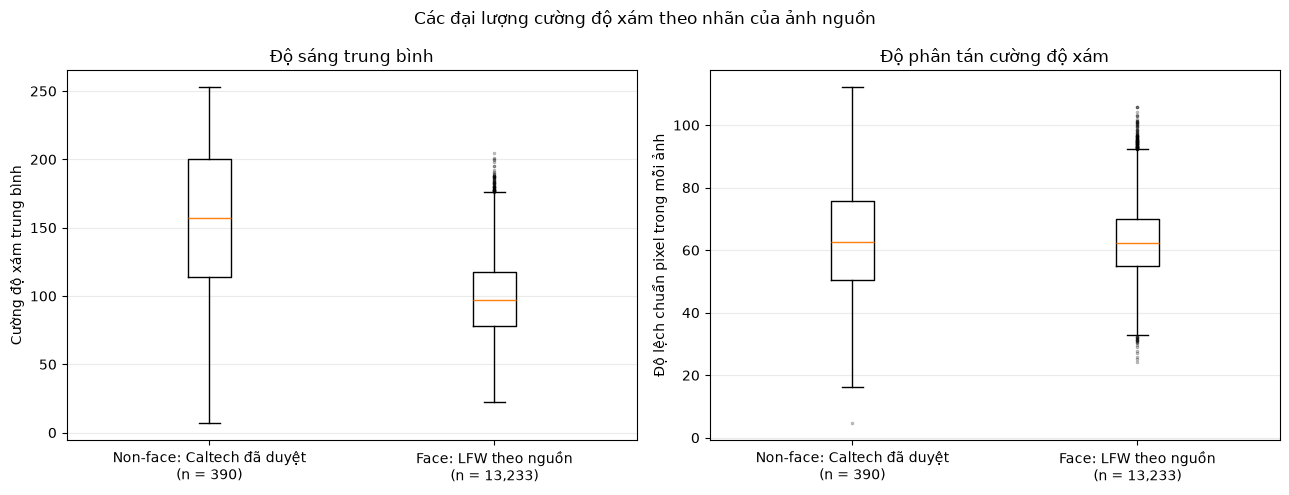

Đã lưu hình: C:\Users\mrddd\Documents\FaceDetection_Week4\reports\figures\eda_gray_features_by_source_label.png


In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

metadata_dir = PROJECT_DIR / "data" / "metadata"
figure_dir = PROJECT_DIR / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# 1. Đọc metadata và thống kê ảnh nguồn
face_sources = pd.read_csv(
    metadata_dir / "lfw_face_sources.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str}
)

background_sources = pd.read_csv(
    metadata_dir / "caltech_background_sources.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str}
)

pixel_stats = pd.read_csv(
    metadata_dir / "eda_source_pixel_stats.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str}
)

# 2. Chọn các ảnh có nhãn phù hợp
face_labels = face_sources.loc[
    pd.to_numeric(face_sources["label"], errors="raise").eq(1),
    ["source_image_id", "label"]
].copy()

background_labels = background_sources.loc[
    background_sources["review_status"].eq("accepted_nonface"),
    ["source_image_id", "label"]
].copy()

# Kiểm tra sự nhất quán giữa trạng thái duyệt và nhãn
background_labels["label"] = pd.to_numeric(
    background_labels["label"], errors="raise"
)

if not background_labels["label"].eq(0).all():
    raise ValueError(
        "Có ảnh accepted_nonface nhưng label không bằng 0."
    )

source_labels = pd.concat(
    [face_labels, background_labels],
    ignore_index=True
)

if (
    source_labels["source_image_id"].isna().any()
    or source_labels["source_image_id"].duplicated().any()
):
    raise ValueError("Mã ảnh nguồn bị thiếu hoặc bị trùng.")

# 3. Ghép bằng mã ảnh, không ghép theo thứ tự dòng
labeled_stats = source_labels.merge(
    pixel_stats,
    on="source_image_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

if not labeled_stats["_merge"].eq("both").all():
    raise ValueError("Có ảnh có nhãn nhưng thiếu thống kê pixel.")

labeled_stats = labeled_stats.drop(columns="_merge")
labeled_stats["label"] = labeled_stats["label"].astype(int)

features = ["mean_gray", "std_gray"]
labeled_stats[features] = labeled_stats[features].apply(
    pd.to_numeric, errors="raise"
)

if not np.isfinite(labeled_stats[features].to_numpy()).all():
    raise ValueError("Có đại lượng ảnh bị thiếu hoặc không hữu hạn.")

labeled_stats["nhom"] = labeled_stats["label"].map({
    0: "Non-face: Caltech đã duyệt",
    1: "Face: LFW theo nguồn"
})

print("Số ảnh trong phân tích:")
print(labeled_stats["nhom"].value_counts())

summary = (
    labeled_stats.groupby("nhom")[features]
    .agg(["count", "mean", "std", "median"])
)

print("\nThống kê theo nhóm nhãn:")
display(summary.round(2))

# 4. Vẽ boxplot theo nhãn
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_settings = [
    ("mean_gray", "Độ sáng trung bình", "Cường độ xám trung bình"),
    ("std_gray", "Độ phân tán cường độ xám",
     "Độ lệch chuẩn pixel trong mỗi ảnh")
]

counts = labeled_stats["label"].value_counts()

for ax, (feature, title, ylabel) in zip(axes, plot_settings):
    values = [
        labeled_stats.loc[labeled_stats["label"].eq(label), feature]
        for label in [0, 1]
    ]

    ax.boxplot(
        values,
        positions=[1, 2],
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.3
        }
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"Non-face: Caltech đã duyệt\n(n = {counts[0]:,})",
        f"Face: LFW theo nguồn\n(n = {counts[1]:,})"
    ])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Các đại lượng cường độ xám theo nhãn của ảnh nguồn")
fig.tight_layout()

figure_path = figure_dir / "eda_gray_features_by_source_label.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

# 5. Lưu kết quả để dùng lại
labeled_stats.to_csv(
    metadata_dir / "eda_labeled_source_pixel_stats.csv",
    index=False,
    encoding="utf-8-sig"
)

summary.to_csv(
    metadata_dir / "eda_gray_features_by_source_label_summary.csv",
    encoding="utf-8-sig"
)

print("Đã lưu hình:", figure_path.resolve())

## Tiêu chí 6 — Kiểm tra chất lượng dữ liệu nguồn

In [56]:
import pandas as pd

metadata_dir = PROJECT_DIR / "data" / "metadata"
report_dir = PROJECT_DIR / "reports" / "tables"
report_dir.mkdir(parents=True, exist_ok=True)

face = pd.read_csv(
    metadata_dir / "lfw_face_sources.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str, "person_id": str}
)

background = pd.read_csv(
    metadata_dir / "caltech_background_sources.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str}
)

# Danh mục toàn bộ ảnh nguồn
catalog = pd.concat(
    [
        face.assign(audit_source="LFW"),
        background.assign(audit_source="Caltech")
    ],
    ignore_index=True
)

# Nhóm nguồn được chọn:
# toàn bộ LFW và chỉ ảnh nền đã được chấp nhận
selected = catalog.loc[
    catalog["audit_source"].eq("LFW")
    | (
        catalog["audit_source"].eq("Caltech")
        & catalog["review_status"].eq("accepted_nonface")
    )
].copy()


def is_blank(series):
    return (
        series.isna()
        | series.fillna("").astype(str).str.strip().eq("")
    )


def duplicate_rows(series):
    # Đếm mọi dòng liên quan đến giá trị trùng;
    # không tính giá trị thiếu.
    values = series.loc[~is_blank(series)].astype(str).str.strip()
    return int(values.duplicated(keep=False).sum())


audit_rows = []

for scope, frame in [
    ("Toàn bộ danh mục nguồn", catalog),
    ("Nhóm nguồn được chọn", selected)
]:
    numeric_label = pd.to_numeric(frame["label"], errors="coerce")

    checks = {
        "Thiếu source_image_id": int(is_blank(frame["source_image_id"]).sum()),
        "Thiếu source_path": int(is_blank(frame["source_path"]).sum()),
        "Thiếu label": int(is_blank(frame["label"]).sum()),
        "Label có giá trị ngoài 0/1": int((
            ~is_blank(frame["label"])
            & ~numeric_label.isin([0, 1])
        ).sum()),
        "Trùng source_image_id: số dòng liên quan":
            duplicate_rows(frame["source_image_id"]),
        "Trùng source_path: số dòng liên quan":
            duplicate_rows(frame["source_path"])
    }

    for issue, count in checks.items():
        audit_rows.append({
            "pham_vi": scope,
            "van_de": issue,
            "so_dong": count,
            "tong_so_dong": len(frame),
            "ty_le_phan_tram": round(100 * count / len(frame), 2)
                if len(frame) else float("nan")
        })

# Kiểm tra nhãn có đúng với vai trò của nguồn hay không
accepted_background = background.loc[
    background["review_status"].eq("accepted_nonface")
]

for issue, frame, expected_label in [
    ("LFW có label khác 1 hoặc thiếu", face, 1),
    ("Nền đã chấp nhận có label khác 0 hoặc thiếu",
     accepted_background, 0)
]:
    labels = pd.to_numeric(frame["label"], errors="coerce")
    audit_rows.append({
        "pham_vi": "Kiểm tra tính nhất quán",
        "van_de": issue,
        "so_dong": int((~labels.isin([expected_label])).sum()),
        "tong_so_dong": len(frame),
        "ty_le_phan_tram": round(
            100 * (~labels.isin([expected_label])).sum() / len(frame), 2
        ) if len(frame) else float("nan")
    })

audit_table = pd.DataFrame(audit_rows)

print("BẢNG KIỂM TRA METADATA")
display(audit_table)

print("\nTRẠNG THÁI DUYỆT NGUỒN NỀN")
display(
    background["review_status"]
    .value_counts(dropna=False)
    .rename_axis("review_status")
    .reset_index(name="so_anh")
)

# Phân bố nhãn trong nhóm nguồn được chọn
selected_labels = pd.to_numeric(selected["label"], errors="coerce")
counts = (
    selected_labels.value_counts()
    .reindex([0, 1], fill_value=0)
)

class_table = counts.rename_axis("label").reset_index(name="so_anh")
class_table["nhom"] = class_table["label"].map({
    0: "Non-face: Caltech đã duyệt",
    1: "Face: LFW theo nguồn"
})
class_table["ty_le_phan_tram"] = (
    100 * class_table["so_anh"] / counts.sum()
).round(2) if counts.sum() else float("nan")

print("\nPHÂN BỐ NHÃN CỦA NHÓM NGUỒN ĐƯỢC CHỌN")
display(class_table)

if counts.loc[0] > 0:
    print(f"Tỷ lệ số ảnh face/non-face: {counts.loc[1] / counts.loc[0]:.2f}:1")

# Kiểm tra nhóm người trong LFW để nhận diện nguy cơ rò rỉ
person_ids = face.loc[~is_blank(face["person_id"]), "person_id"]
person_counts = person_ids.value_counts()
repeated_people = person_counts.loc[person_counts > 1]

print("\nTHÔNG TIN NHÓM NGƯỜI TRONG LFW")
print("Số ảnh thiếu person_id:", int(is_blank(face["person_id"]).sum()))
print("Số person_id có nhiều hơn một ảnh:", len(repeated_people))
print("Số ảnh thuộc các person_id này:", int(repeated_people.sum()))

# Lưu minh chứng, giữ nguyên các CSV nguồn
audit_table.to_csv(
    report_dir / "quality_source_metadata_audit.csv",
    index=False,
    encoding="utf-8-sig"
)
class_table.to_csv(
    report_dir / "quality_source_label_counts.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu các bảng vào:", report_dir.resolve())

BẢNG KIỂM TRA METADATA


,pham_vi,van_de,so_dong,tong_so_dong,ty_le_phan_tram
0,Toàn bộ danh mục nguồn,Thiếu source_image_id,0,13700,0.00
1,Toàn bộ danh mục nguồn,Thiếu source_path,0,13700,0.00
2,Toàn bộ danh mục nguồn,Thiếu label,77,13700,0.56
3,Toàn bộ danh mục nguồn,Label có giá trị ngoài 0/1,0,13700,0.00
4,Toàn bộ danh mục nguồn,Trùng source_image_id: số dòng liên quan,0,13700,0.00
5,Toàn bộ danh mục nguồn,Trùng source_path: số dòng liên quan,0,13700,0.00
6,Nhóm nguồn được chọn,Thiếu source_image_id,0,13623,0.00
7,Nhóm nguồn được chọn,Thiếu source_path,0,13623,0.00
8,Nhóm nguồn được chọn,Thiếu label,0,13623,0.00
9,Nhóm nguồn được chọn,Label có giá trị ngoài 0/1,0,13623,0.00



TRẠNG THÁI DUYỆT NGUỒN NỀN


,review_status,so_anh
0,accepted_nonface,390
1,rejected_face,71
2,uncertain,6



PHÂN BỐ NHÃN CỦA NHÓM NGUỒN ĐƯỢC CHỌN


,label,so_anh,nhom,ty_le_phan_tram
0,0,390,Non-face: Caltech đã duyệt,2.86
1,1,13233,Face: LFW theo nguồn,97.14


Tỷ lệ số ảnh face/non-face: 33.93:1

THÔNG TIN NHÓM NGƯỜI TRONG LFW
Số ảnh thiếu person_id: 0
Số person_id có nhiều hơn một ảnh: 1680
Số ảnh thuộc các person_id này: 9164

Đã lưu các bảng vào: C:\Users\mrddd\Documents\FaceDetection_Week4\reports\tables


In [57]:
from pathlib import Path
from io import BytesIO
from PIL import Image, ImageOps
import hashlib
import pandas as pd

# Dùng catalog và selected từ cell kiểm tra metadata
selected_ids = set(selected["source_image_id"])
extension_formats = Image.registered_extensions()

records = []

for number, row in enumerate(catalog.itertuples(index=False), start=1):
    image_path = Path(row.source_path)

    if not image_path.is_absolute():
        image_path = PROJECT_DIR / image_path

    result = {
        "source_image_id": row.source_image_id,
        "source_path": str(image_path),
        "nguon": row.audit_source,
        "duoc_chon": row.source_image_id in selected_ids,
        "status": "ok",
        "image_format": None,
        "width": None,
        "height": None,
        "extension_issue": False,
        "smaller_than_24": False,
        "file_sha256": None,
        "pixel_sha256": None,
        "error": ""
    }

    try:
        # Băm nội dung tệp
        raw_bytes = image_path.read_bytes()
        result["file_sha256"] = hashlib.sha256(raw_bytes).hexdigest()

        with Image.open(BytesIO(raw_bytes)) as image:
            actual_format = image.format
            image.load()  # Giải mã ảnh để phát hiện lỗi đọc

            result["image_format"] = actual_format
            expected_format = extension_formats.get(
                image_path.suffix.lower()
            )
            result["extension_issue"] = (
                expected_format is None
                or expected_format != actual_format
            )

            # Chuẩn hóa hướng EXIF và chế độ RGB để so sánh pixel.
            # Giữ nguyên kích thước, không resize.
            rgb = ImageOps.exif_transpose(image).convert("RGB")
            width, height = rgb.size

            result["width"] = width
            result["height"] = height
            result["smaller_than_24"] = min(width, height) < 24

            pixel_hash = hashlib.sha256()
            pixel_hash.update(f"{width},{height},RGB:".encode("ascii"))
            pixel_hash.update(rgb.tobytes())
            result["pixel_sha256"] = pixel_hash.hexdigest()

    except FileNotFoundError as error:
        result["status"] = "missing_file"
        result["error"] = str(error)

    except Exception as error:
        result["status"] = "read_or_decode_error"
        result["error"] = f"{type(error).__name__}: {error}"

    records.append(result)

    if number % 1000 == 0 or number == len(catalog):
        print(f"Đã kiểm tra {number:,}/{len(catalog):,} ảnh")

file_checks = pd.DataFrame(records)


def duplicate_stats(series):
    counts = series.dropna().value_counts()
    repeated = counts.loc[counts > 1]

    return {
        "groups": len(repeated),
        "related_rows": int(repeated.sum()),
        "extra_rows": int((repeated - 1).sum())
    }


summary_rows = []

for scope, frame in [
    ("Toàn bộ danh mục nguồn", file_checks),
    ("Nhóm nguồn được chọn",
     file_checks.loc[file_checks["duoc_chon"]])
]:
    byte_duplicates = duplicate_stats(frame["file_sha256"])
    pixel_duplicates = duplicate_stats(frame["pixel_sha256"])

    metrics = {
        "Không tìm thấy tệp":
            int(frame["status"].eq("missing_file").sum()),

        "Lỗi đọc hoặc giải mã ảnh":
            int(frame["status"].eq("read_or_decode_error").sum()),

        "Đuôi tệp không phù hợp hoặc không nhận diện":
            int(frame["extension_issue"].sum()),

        "Ảnh có chiều nhỏ hơn 24 pixel":
            int(frame["smaller_than_24"].sum()),

        "Số dòng thuộc nhóm tệp trùng hoàn toàn":
            byte_duplicates["related_rows"],

        "Số nhóm ảnh trùng pixel RGB":
            pixel_duplicates["groups"],

        "Số dòng thuộc nhóm ảnh trùng pixel RGB":
            pixel_duplicates["related_rows"],

        "Số ảnh dư nếu giữ một ảnh mỗi nhóm trùng pixel":
            pixel_duplicates["extra_rows"]
    }

    for issue, count in metrics.items():
        summary_rows.append({
            "pham_vi": scope,
            "kiem_tra": issue,
            "so_luong": count
        })

file_summary = pd.DataFrame(summary_rows)

print("\nBẢNG KIỂM TRA TỆP ẢNH VÀ TRÙNG NỘI DUNG")
display(file_summary)

# Danh sách các ảnh liên quan đến nhóm trùng pixel
duplicate_mask = (
    file_checks["pixel_sha256"].notna()
    & file_checks["pixel_sha256"].duplicated(keep=False)
)

duplicate_images = (
    file_checks.loc[duplicate_mask]
    .sort_values("pixel_sha256")
)

if not duplicate_images.empty:
    print("\nMột số ảnh thuộc nhóm trùng pixel:")
    display(
        duplicate_images[
            ["source_image_id", "nguon", "duoc_chon", "pixel_sha256"]
        ].head(20)
    )

report_dir = PROJECT_DIR / "reports" / "tables"
report_dir.mkdir(parents=True, exist_ok=True)

for filename, table in [
    ("quality_source_file_checks.csv", file_checks),
    ("quality_source_file_summary.csv", file_summary),
    ("quality_source_pixel_duplicates.csv", duplicate_images)
]:
    table.to_csv(
        report_dir / filename,
        index=False,
        encoding="utf-8-sig"
    )

print("Đã lưu kết quả vào:", report_dir.resolve())

Đã kiểm tra 1,000/13,700 ảnh
Đã kiểm tra 2,000/13,700 ảnh
Đã kiểm tra 3,000/13,700 ảnh
Đã kiểm tra 4,000/13,700 ảnh
Đã kiểm tra 5,000/13,700 ảnh
Đã kiểm tra 6,000/13,700 ảnh
Đã kiểm tra 7,000/13,700 ảnh
Đã kiểm tra 8,000/13,700 ảnh
Đã kiểm tra 9,000/13,700 ảnh
Đã kiểm tra 10,000/13,700 ảnh
Đã kiểm tra 11,000/13,700 ảnh
Đã kiểm tra 12,000/13,700 ảnh
Đã kiểm tra 13,000/13,700 ảnh
Đã kiểm tra 13,700/13,700 ảnh

BẢNG KIỂM TRA TỆP ẢNH VÀ TRÙNG NỘI DUNG


,pham_vi,kiem_tra,so_luong
0,Toàn bộ danh mục nguồn,Không tìm thấy tệp,0
1,Toàn bộ danh mục nguồn,Lỗi đọc hoặc giải mã ảnh,0
2,Toàn bộ danh mục nguồn,Đuôi tệp không phù hợp hoặc không nhận diện,0
3,Toàn bộ danh mục nguồn,Ảnh có chiều nhỏ hơn 24 pixel,0
4,Toàn bộ danh mục nguồn,Số dòng thuộc nhóm tệp trùng hoàn toàn,0
5,Toàn bộ danh mục nguồn,Số nhóm ảnh trùng pixel RGB,0
6,Toàn bộ danh mục nguồn,Số dòng thuộc nhóm ảnh trùng pixel RGB,0
7,Toàn bộ danh mục nguồn,Số ảnh dư nếu giữ một ảnh mỗi nhóm trùng pixel,0
8,Nhóm nguồn được chọn,Không tìm thấy tệp,0
9,Nhóm nguồn được chọn,Lỗi đọc hoặc giải mã ảnh,0


Đã lưu kết quả vào: C:\Users\mrddd\Documents\FaceDetection_Week4\reports\tables


In [58]:
import numpy as np
import pandas as pd

metadata_dir = PROJECT_DIR / "data" / "metadata"
report_dir = PROJECT_DIR / "reports" / "tables"
report_dir.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(
    metadata_dir / "eda_labeled_source_pixel_stats.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str}
)

if data["source_image_id"].isna().any():
    raise ValueError("Có mã ảnh bị thiếu.")

if data["source_image_id"].duplicated().any():
    raise ValueError("Có mã ảnh bị trùng.")

# Miền hợp lệ: std_gray được tính bằng độ lệch chuẩn
# tổng thể của pixel (NumPy std mặc định ddof=0).
limits = {
    "mean_gray": (0, 255),
    "std_gray": (0, 127.5)
}

summary_rows = []
outlier_parts = []

for group_name, group in data.groupby("nhom"):
    for feature, (minimum, maximum) in limits.items():
        values = pd.to_numeric(group[feature], errors="coerce")

        valid = (
            np.isfinite(values)
            & values.between(minimum, maximum + 1e-6)
        )
        valid_values = values.loc[valid]

        q1 = valid_values.quantile(0.25)
        q3 = valid_values.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        flagged = valid & (
            values.lt(lower) | values.gt(upper)
        )

        summary_rows.append({
            "nhom": group_name,
            "dai_luong": feature,
            "so_anh": len(group),
            "thieu_hoac_ngoai_mien_hop_le": int((~valid).sum()),
            "Q1": q1,
            "Q3": q3,
            "can_duoi": lower,
            "can_tren": upper,
            "so_anh_ngoai_lai_IQR": int(flagged.sum()),
            "ty_le_tren_anh_hop_le": (
                100 * flagged.sum() / valid.sum()
                if valid.sum() else float("nan")
            )
        })

        details = group.loc[
            flagged, ["source_image_id", "nhom"]
        ].copy()
        details["dai_luong"] = feature
        details["gia_tri"] = values.loc[flagged]
        details["can_duoi"] = lower
        details["can_tren"] = upper
        outlier_parts.append(details)

outlier_summary = pd.DataFrame(summary_rows)
outlier_details = pd.concat(outlier_parts, ignore_index=True)

print("KIỂM TRA NGOẠI LAI TRÊN NHÓM NGUỒN ĐƯỢC CHỌN")
display(outlier_summary.round(2))

print(
    "\nSố ảnh được gắn cờ ở ít nhất một đại lượng:",
    outlier_details["source_image_id"].nunique()
)

outlier_summary.to_csv(
    report_dir / "quality_source_outlier_summary.csv",
    index=False,
    encoding="utf-8-sig"
)
outlier_details.to_csv(
    report_dir / "quality_source_outliers_iqr.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả vào:", report_dir.resolve())

KIỂM TRA NGOẠI LAI TRÊN NHÓM NGUỒN ĐƯỢC CHỌN


,nhom,dai_luong,so_anh,thieu_hoac_ngoai_mien_hop_le,Q1,Q3,can_duoi,can_tren,so_anh_ngoai_lai_IQR,ty_le_tren_anh_hop_le
0,Face: LFW theo nguồn,mean_gray,13233,0,78.39,117.57,19.61,176.35,67,0.51
1,Face: LFW theo nguồn,std_gray,13233,0,54.94,69.90,32.50,92.34,141,1.07
2,Non-face: Caltech đã duyệt,mean_gray,390,0,114.22,200.00,-14.46,328.68,0,0.00
3,Non-face: Caltech đã duyệt,std_gray,390,0,50.34,75.85,12.08,114.12,1,0.26



Số ảnh được gắn cờ ở ít nhất một đại lượng: 208
Đã lưu kết quả vào: C:\Users\mrddd\Documents\FaceDetection_Week4\reports\tables


In [59]:
import pandas as pd

metadata_dir = PROJECT_DIR / "data" / "metadata"
report_dir = PROJECT_DIR / "reports" / "tables"
report_dir.mkdir(parents=True, exist_ok=True)

# 1. Đọc metadata hiện tại
face = pd.read_csv(
    metadata_dir / "lfw_face_sources.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str, "person_id": str}
)
background = pd.read_csv(
    metadata_dir / "caltech_background_sources.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str}
)

face["source_kind"] = "LFW"
background["source_kind"] = "Caltech"

allowed_statuses = {
    "accepted_nonface", "rejected_face", "uncertain"
}
if not background["review_status"].isin(allowed_statuses).all():
    raise ValueError("Nguồn nền còn trạng thái chưa xử lý hoặc không hợp lệ.")

catalog = pd.concat([face, background], ignore_index=True)

# 2. Chọn nguồn theo kết quả duyệt
keep_mask = (
    catalog["source_kind"].eq("LFW")
    | (
        catalog["source_kind"].eq("Caltech")
        & catalog["review_status"].eq("accepted_nonface")
    )
)

clean_sources = catalog.loc[keep_mask].copy()
excluded_sources = catalog.loc[~keep_mask].copy()

# Kiểm tra các trường bắt buộc của nhóm được giữ
for column in ["source_image_id", "source_path"]:
    missing = (
        clean_sources[column].isna()
        | clean_sources[column].fillna("").astype(str).str.strip().eq("")
    )
    if missing.any():
        raise ValueError(f"Nhóm được giữ còn thiếu {column}.")

if clean_sources["source_image_id"].duplicated().any():
    raise ValueError("Nhóm được giữ có mã ảnh trùng.")

labels = pd.to_numeric(clean_sources["label"], errors="raise")
expected_labels = clean_sources["source_kind"].map({
    "LFW": 1,
    "Caltech": 0
})

if not labels.eq(expected_labels).all():
    raise ValueError("Có nhãn không phù hợp với nguồn được chọn.")

clean_sources["label"] = labels.astype(int)

excluded_sources["exclusion_reason"] = (
    excluded_sources["review_status"].map({
        "rejected_face": "Có khuôn mặt; loại khỏi nguồn mẫu âm",
        "uncertain": "Chưa chắc chắn; tạm thời không sử dụng"
    })
)

# 3. Giữ ảnh ngoại lai kèm cờ, không lọc theo IQR
outliers = pd.read_csv(
    report_dir / "quality_source_outliers_iqr.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str}
)

if not set(outliers["source_image_id"]).issubset(
    set(clean_sources["source_image_id"])
):
    raise ValueError("Danh sách ngoại lai không khớp nguồn hiện tại.")

flagged_features = outliers.groupby("source_image_id")["dai_luong"].agg(
    lambda values: ";".join(sorted(set(values)))
)

clean_sources["iqr_flagged_features"] = (
    clean_sources["source_image_id"].map(flagged_features).fillna("")
)
clean_sources["iqr_flag"] = (
    clean_sources["iqr_flagged_features"].ne("")
)

# 4. Chuẩn bị mã nhóm cho bước chia tập
is_face = clean_sources["source_kind"].eq("LFW")
person_ids = clean_sources.loc[is_face, "person_id"]

if (
    person_ids.isna()
    | person_ids.fillna("").astype(str).str.strip().eq("")
).any():
    raise ValueError("Có ảnh LFW thiếu person_id để tạo nhóm.")

clean_sources["split_group"] = ""

clean_sources.loc[is_face, "split_group"] = (
    "lfw_person:"
    + clean_sources.loc[is_face, "person_id"].astype(str)
)

clean_sources.loc[~is_face, "split_group"] = (
    "caltech_image:"
    + clean_sources.loc[~is_face, "source_image_id"].astype(str)
)

# 5. So sánh trước–sau bước lọc danh mục đã duyệt
def summarize_sources(frame):
    numeric_labels = pd.to_numeric(frame["label"], errors="raise")
    is_background = frame["source_kind"].eq("Caltech")

    return {
        "Tổng số ảnh nguồn": len(frame),
        "Số ảnh có nhãn trống": int(numeric_labels.isna().sum()),
        "Số ảnh mang nhãn face": int(numeric_labels.eq(1).sum()),
        "Số ảnh mang nhãn non-face": int(numeric_labels.eq(0).sum()),
        "Nguồn nền bị loại vì có mặt": int((
            is_background & frame["review_status"].eq("rejected_face")
        ).sum()),
        "Nguồn nền chưa chắc chắn": int((
            is_background & frame["review_status"].eq("uncertain")
        ).sum())
    }

before_after = pd.DataFrame({
    "Trước lọc: danh mục đã duyệt": summarize_sources(catalog),
    "Sau lọc: nguồn được giữ": summarize_sources(clean_sources)
})
before_after.index.name = "chi_tieu"

print("BẢNG TRƯỚC–SAU XỬ LÝ NGUỒN")
display(before_after)

print(
    "\nSố ảnh giữ lại kèm cờ IQR:",
    int(clean_sources["iqr_flag"].sum())
)
print("Số nhóm phục vụ chia tập:", clean_sources["split_group"].nunique())

# 6. Lưu minh chứng
clean_sources.to_csv(
    metadata_dir / "clean_source_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)
excluded_sources.to_csv(
    metadata_dir / "excluded_source_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)
before_after.to_csv(
    report_dir / "quality_source_before_after.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu danh sách nguồn được giữ, nguồn loại và bảng trước–sau.")

BẢNG TRƯỚC–SAU XỬ LÝ NGUỒN


,Trước lọc: danh mục đã duyệt,Sau lọc: nguồn được giữ
chi_tieu,,
Tổng số ảnh nguồn,13700,13623
Số ảnh có nhãn trống,77,0
Số ảnh mang nhãn face,13233,13233
Số ảnh mang nhãn non-face,390,390
Nguồn nền bị loại vì có mặt,71,0
Nguồn nền chưa chắc chắn,6,0



Số ảnh giữ lại kèm cờ IQR: 208
Số nhóm phục vụ chia tập: 6139

Đã lưu danh sách nguồn được giữ, nguồn loại và bảng trước–sau.


In [60]:
from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
import cv2
import hashlib

SEED = 42
SIZE = 24
MAX_FACE = 1800
MAX_NONFACE = 1800

if "lfw" not in globals():
    raise RuntimeError(
        "Hãy chạy cell tải LFW trong notebook trước."
    )

manifest = pd.read_csv(
    PROJECT_DIR / "data" / "metadata" / "clean_source_manifest.csv",
    encoding="utf-8-sig",
    dtype={"source_image_id": str}
)

background_sources = manifest.loc[
    manifest["source_kind"].eq("Caltech")
    & manifest["review_status"].eq("accepted_nonface")
    & manifest["label"].eq(0)
].copy()

if background_sources.empty:
    raise ValueError("Không có nguồn nền đã được chấp nhận.")

# 1. Tạo mẫu face từ ảnh LFW đã tải
face_rng = np.random.default_rng(SEED)
indices = face_rng.choice(
    len(lfw.images),
    size=min(MAX_FACE, len(lfw.images)),
    replace=False
)

face_min = float(np.nanmin(lfw.images))
face_max = float(np.nanmax(lfw.images))

if not (0 <= face_min <= face_max <= 255):
    raise ValueError("Thang giá trị ảnh LFW không hợp lệ.")

face_scale = 255.0 if face_max <= 1.0 else 1.0
positive = []

for index in indices:
    original = np.asarray(lfw.images[index], dtype=np.float32)

    if not np.isfinite(original).all():
        raise ValueError(f"Ảnh LFW {index} có giá trị không hữu hạn.")

    patch = cv2.resize(
        original * face_scale,
        (SIZE, SIZE),
        interpolation=cv2.INTER_AREA
    )
    patch = np.clip(np.rint(patch), 0, 255).astype(np.uint8)
    person = int(lfw.target[index])

    positive.append({
        "image": patch,
        "label": 1,
        "source": "LFW",
        "source_id": f"lfw_{int(index)}",
        "group": f"lfw_person:{person}",
        "person_id": str(lfw.target_names[person]),
        "origin": "LFW: ROI từ cell fetch_lfw_people"
    })

# 2. Phân bổ số crop cho các nguồn nền
# Với 390 nguồn và 1.800 crop: mỗi nguồn nhận 4 hoặc 5 crop.
background_sources = background_sources.sample(
    frac=1, random_state=SEED
).reset_index(drop=True)

base, remainder = divmod(MAX_NONFACE, len(background_sources))
crop_rng = np.random.default_rng(SEED + 1)
negative = []

for position, row in background_sources.iterrows():
    quota = base + int(position < remainder)

    if quota == 0:
        continue

    image_path = Path(row["source_path"])
    if not image_path.is_absolute():
        image_path = PROJECT_DIR / image_path

    with Image.open(image_path) as image:
        gray = np.asarray(
            ImageOps.exif_transpose(image).convert("L")
        )

    height, width = gray.shape

    if min(height, width) < SIZE:
        raise ValueError(f"Ảnh nền quá nhỏ: {image_path}")

    maximum_side = max(SIZE, min(height, width) // 2)

    for crop_number in range(quota):
        side = int(crop_rng.integers(SIZE, maximum_side + 1))
        x = int(crop_rng.integers(0, width - side + 1))
        y = int(crop_rng.integers(0, height - side + 1))

        patch = cv2.resize(
            gray[y:y + side, x:x + side],
            (SIZE, SIZE),
            interpolation=cv2.INTER_AREA
        )

        negative.append({
            "image": patch,
            "label": 0,
            "source": "Caltech đã duyệt",
            "source_id": (
                f"{row['source_image_id']}:crop{crop_number}"
            ),
            "source_image_id": row["source_image_id"],
            "group": row["split_group"],
            "origin": str(image_path),
            "crop_x": x,
            "crop_y": y,
            "crop_side": side
        })

# 3. Kiểm tra trùng pixel sau crop/resize
# Ảnh nguồn không trùng vẫn có thể tạo ra các crop trùng.
df_raw = pd.DataFrame(positive + negative)

df_raw["sha256"] = df_raw["image"].map(
    lambda image: hashlib.sha256(
        np.ascontiguousarray(image).tobytes()
    ).hexdigest()
)

conflicts = df_raw.groupby("sha256")["label"].nunique().gt(1)
if conflicts.any():
    raise ValueError(
        f"Có {int(conflicts.sum())} nhóm pixel trùng nhưng khác nhãn; "
        "cần kiểm tra trước khi tiếp tục."
    )

duplicates = int(df_raw.duplicated("sha256").sum())
df = (
    df_raw.drop_duplicates("sha256", keep="first")
    .reset_index(drop=True)
    .copy()
)

images_u8 = np.stack(df["image"].to_numpy())

assert images_u8.shape[1:] == (SIZE, SIZE)
assert images_u8.dtype == np.uint8

df["mean_gray"] = images_u8.mean(axis=(1, 2))
df["std_gray"] = images_u8.std(axis=(1, 2))

print("Số mẫu trước kiểm tra trùng:", len(df_raw))
print("Số bản sao pixel đã loại:", duplicates)
print("Kích thước mảng ảnh:", images_u8.shape)
print("Kiểu dữ liệu:", images_u8.dtype)
print("Khoảng pixel:", images_u8.min(), "đến", images_u8.max())

print("\nSố mẫu và số nhóm sau kiểm tra:")
display(
    df.groupby("label").agg(
        so_mau=("source_id", "size"),
        so_nhom=("group", "nunique")
    ).rename(index={0: "Non-face", 1: "Face"})
)

# 4. Lưu mẫu và metadata theo cùng thứ tự dòng
processed_dir = PROJECT_DIR / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

np.save(processed_dir / "images_24x24.npy", images_u8)

df.drop(columns="image").to_csv(
    processed_dir / "patch_metadata_before_split.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu ảnh 24×24 và metadata trước chia tập.")

Số mẫu trước kiểm tra trùng: 3600
Số bản sao pixel đã loại: 11
Kích thước mảng ảnh: (3589, 24, 24)
Kiểu dữ liệu: uint8
Khoảng pixel: 0 đến 255

Số mẫu và số nhóm sau kiểm tra:


,so_mau,so_nhom
label,,
Non-face,1789,390
Face,1800,1224



Đã lưu ảnh 24×24 và metadata trước chia tập.


## tiêu chí 8

In [61]:
import numpy as np
import pandas as pd
import hashlib
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
processed_dir = PROJECT_DIR / "data" / "processed"
report_dir = PROJECT_DIR / "reports" / "tables"
report_dir.mkdir(parents=True, exist_ok=True)

# 1. Đọc ảnh và metadata theo cùng thứ tự dòng đã lưu
images_u8 = np.load(processed_dir / "images_24x24.npy")

df = pd.read_csv(
    processed_dir / "patch_metadata_before_split.csv",
    encoding="utf-8-sig",
    dtype={
        "source_id": str,
        "source_image_id": str,
        "group": str,
        "sha256": str
    }
)

assert images_u8.shape == (len(df), 24, 24)
assert images_u8.dtype == np.uint8
assert df["label"].isin([0, 1]).all()
assert not df[["source_id", "group", "sha256"]].isna().any().any()
assert not df["sha256"].duplicated().any()

# Kiểm tra ảnh và metadata vẫn khớp thứ tự
actual_hashes = [
    hashlib.sha256(np.ascontiguousarray(image).tobytes()).hexdigest()
    for image in images_u8
]
assert actual_hashes == df["sha256"].tolist(), (
    "Thứ tự ảnh và metadata không khớp."
)

# Giữ cột image để tương thích với các cell EDA của notebook
df["image"] = list(images_u8)

assert df.groupby("group")["label"].nunique().max() == 1

# 2. Chia riêng từng lớp theo nhóm, rồi ghép kết quả
def split_one_class(frame, seed):
    if frame["group"].nunique() < 3:
        raise ValueError("Không đủ nhóm để chia ba tập.")

    first = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=seed
    )
    remaining_pos, test_pos = next(
        first.split(frame, groups=frame["group"])
    )

    remaining = frame.iloc[remaining_pos]

    second = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15 / 0.85,
        random_state=seed + 10
    )
    train_pos, val_pos = next(
        second.split(remaining, groups=remaining["group"])
    )

    return (
        remaining.iloc[train_pos].index,
        remaining.iloc[val_pos].index,
        frame.iloc[test_pos].index
    )

df["split"] = ""

for label in [0, 1]:
    subset = df.loc[df["label"].eq(label)]
    train_idx, val_idx, test_idx = split_one_class(
        subset, seed=SEED + label
    )

    df.loc[train_idx, "split"] = "train"
    df.loc[val_idx, "split"] = "val"
    df.loc[test_idx, "split"] = "test"

assert df["split"].isin(["train", "val", "test"]).all()
assert df.groupby("split")["label"].nunique().eq(2).all()

# 3. Kiểm tra giao nhau giữa từng cặp tập
audit_rows = []

for first_name, second_name in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    first = df.loc[df["split"].eq(first_name)]
    second = df.loc[df["split"].eq(second_name)]

    # Chỉ kiểm tra source_image_id ở lớp nền;
    # lớp face được kiểm soát theo nhóm người.
    first_bg = first.loc[first["label"].eq(0)]
    second_bg = second.loc[second["label"].eq(0)]

    audit_rows.append({
        "cap_tap": f"{first_name} / {second_name}",
        "nhom_giao_nhau": len(
            set(first["group"]) & set(second["group"])
        ),
        "hash_pixel_giao_nhau": len(
            set(first["sha256"]) & set(second["sha256"])
        ),
        "anh_nen_goc_giao_nhau": len(
            set(first_bg["source_image_id"].dropna())
            & set(second_bg["source_image_id"].dropna())
        )
    })

leakage_audit = pd.DataFrame(audit_rows)

assert leakage_audit[
    ["nhom_giao_nhau", "hash_pixel_giao_nhau", "anh_nen_goc_giao_nhau"]
].eq(0).all().all(), "Phát hiện giao nhau giữa các tập!"

# 4. Thống kê kích thước thực tế
split_order = ["train", "val", "test"]

split_summary = (
    pd.crosstab(df["split"], df["label"])
    .reindex(index=split_order, columns=[0, 1], fill_value=0)
    .rename(columns={0: "Non-face", 1: "Face"})
)
split_summary["tong_mau"] = (
    split_summary["Non-face"] + split_summary["Face"]
)
split_summary["ty_le_phan_tram"] = (
    100 * split_summary["tong_mau"] / len(df)
).round(2)
split_summary["so_nhom"] = (
    df.groupby("split")["group"].nunique().reindex(split_order)
)

print("PHÂN BỐ CÁC TẬP")
display(split_summary)

print("\nKIỂM TRA GIAO NHAU GIỮA CÁC TẬP")
display(leakage_audit)

# 5. Lưu metadata và chỉ số dòng để sử dụng với ma trận X
df.drop(columns="image").to_csv(
    processed_dir / "metadata.csv",
    index=False,
    encoding="utf-8-sig"
)

np.savez(
    processed_dir / "split_indices.npz",
    **{
        name: np.flatnonzero(df["split"].eq(name).to_numpy())
        for name in split_order
    }
)

split_summary.to_csv(
    report_dir / "split_summary.csv",
    encoding="utf-8-sig"
)
leakage_audit.to_csv(
    report_dir / "split_leakage_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu metadata có cột split và chỉ số dòng của từng tập.")

PHÂN BỐ CÁC TẬP


label,Non-face,Face,tong_mau,ty_le_phan_tram,so_nhom
split,,,,,
train,1234,1277,2511,69.96,1128
val,260,280,540,15.05,243
test,295,243,538,14.99,243



KIỂM TRA GIAO NHAU GIỮA CÁC TẬP


,cap_tap,nhom_giao_nhau,hash_pixel_giao_nhau,anh_nen_goc_giao_nhau
0,train / val,0,0,0
1,train / test,0,0,0
2,val / test,0,0,0


Đã lưu metadata có cột split và chỉ số dòng của từng tập.


In [62]:
import numpy as np
import pandas as pd

SIZE = 24

# 1. Chuẩn hóa pixel bằng hằng số 255, không cần fit
images = images_u8.astype(np.float32) / 255.0

# Ảnh tích phân có thêm một hàng và một cột 0
ii = np.pad(
    images,
    ((0, 0), (1, 0), (1, 0))
).cumsum(axis=1, dtype=np.float64).cumsum(axis=2, dtype=np.float64)


def rectangle_sum(II, x, y, width, height):
    return (
        II[:, y + height, x + width]
        - II[:, y, x + width]
        - II[:, y + height, x]
        + II[:, y, x]
    )


# 2. Định nghĩa mẫu:
# mỗi bộ ba là (vị trí ô theo x, vị trí ô theo y, trọng số)
patterns = {
    "two_x": [(0, 0, -1), (1, 0, 1)],
    "two_y": [(0, 0, -1), (0, 1, 1)],
    "three_x": [(0, 0, 1), (1, 0, -2), (2, 0, 1)],
    "three_y": [(0, 0, 1), (0, 1, -2), (0, 2, 1)],
    "four": [
        (0, 0, 1), (1, 0, -1),
        (0, 1, -1), (1, 1, 1)
    ]
}

# Cố định cạnh ô 4, 6, 8 pixel và bước dịch 4 pixel
specs = []

for block in (4, 6, 8):
    for kind, pattern in patterns.items():
        width = (max(dx for dx, dy, weight in pattern) + 1) * block
        height = (max(dy for dx, dy, weight in pattern) + 1) * block

        for y in range(0, SIZE - height + 1, 4):
            for x in range(0, SIZE - width + 1, 4):
                specs.append((kind, x, y, block))

# 3. Trích xuất đặc trưng theo cùng thứ tự ảnh
X = np.empty((len(images), len(specs)), dtype=np.float32)

for column, (kind, x, y, block) in enumerate(specs):
    values = np.zeros(len(images), dtype=np.float64)

    for dx, dy, weight in patterns[kind]:
        values += weight * rectangle_sum(
            ii,
            x + dx * block,
            y + dy * block,
            block,
            block
        )

    # Chuẩn hóa theo diện tích các ô
    factor = 1 if kind in ("two_x", "two_y") else 2
    X[:, column] = values / (factor * block * block)

y = df["label"].to_numpy(dtype=np.int64)

assert X.shape == (len(df), len(specs))
assert np.isfinite(X).all()
assert len(y) == len(X)

# 4. Tạo từ điển đặc trưng
feature_names = [
    f"haar_{kind}_x{x}_y{y0}_b{block}"
    for kind, x, y0, block in specs
]

feature_dict = pd.DataFrame(
    specs, columns=["type", "x", "y", "block"]
)
feature_dict.insert(0, "feature", feature_names)
feature_dict["description"] = feature_dict["type"].map({
    "two_x": "Trung bình ô phải trừ ô trái",
    "two_y": "Trung bình ô dưới trừ ô trên",
    "three_x": "Trung bình hai ô ngoài trừ ô giữa, theo ngang",
    "three_y": "Trung bình hai ô ngoài trừ ô giữa, theo dọc",
    "four": "Trung bình hai ô chéo chính trừ hai ô chéo phụ"
})

# 5. Lấy các ma trận theo split đã xác định
train_mask = df["split"].eq("train").to_numpy()
val_mask = df["split"].eq("val").to_numpy()
test_mask = df["split"].eq("test").to_numpy()

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

feature_summary = pd.DataFrame({
    "tap": ["train", "val", "test"],
    "so_mau": [len(X_train), len(X_val), len(X_test)],
    "so_dac_trung": [X.shape[1]] * 3
})

print("Kích thước X:", X.shape)
print("Kiểu dữ liệu X:", X.dtype)
print("X có toàn bộ giá trị hữu hạn:", np.isfinite(X).all())
display(feature_summary)

print("\nVí dụ từ điển đặc trưng:")
display(feature_dict.head())

# 6. Lưu để dùng lại khi huấn luyện
processed_dir = PROJECT_DIR / "data" / "processed"

np.save(processed_dir / "haar_features.npy", X)
np.save(processed_dir / "labels.npy", y)

feature_dict.to_csv(
    processed_dir / "data_dictionary_haar.csv",
    index=False,
    encoding="utf-8-sig"
)

np.savez_compressed(
    processed_dir / "haar_dataset_splits.npz",
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test
)

feature_summary.to_csv(
    PROJECT_DIR / "reports" / "tables" / "feature_matrix_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu ma trận Haar-like, nhãn, từ điển và các tập dữ liệu.")

Kích thước X: (3589, 258)
Kiểu dữ liệu X: float32
X có toàn bộ giá trị hữu hạn: True


,tap,so_mau,so_dac_trung
0,train,2511,258
1,val,540,258
2,test,538,258



Ví dụ từ điển đặc trưng:


,feature,type,x,y,block,description
0,haar_two_x_x0_y0_b4,two_x,0,0,4,Trung bình ô phải trừ ô trái
1,haar_two_x_x4_y0_b4,two_x,4,0,4,Trung bình ô phải trừ ô trái
2,haar_two_x_x8_y0_b4,two_x,8,0,4,Trung bình ô phải trừ ô trái
3,haar_two_x_x12_y0_b4,two_x,12,0,4,Trung bình ô phải trừ ô trái
4,haar_two_x_x16_y0_b4,two_x,16,0,4,Trung bình ô phải trừ ô trái


Đã lưu ma trận Haar-like, nhãn, từ điển và các tập dữ liệu.
